> **Parte 1 del estudio: fase exploratoria y primeras confirmaciones.** Este cuaderno contiene los datos, el filtro de plantillas, el descubrimiento N05 y las rondas 1 a 3 con las variables originales. Sus resultados llevaron a **revisar las variables**. La confirmación final con biografías nuevas, las dimensiones, los gráficos radiales y la métrica de sesgo están en la **parte 2**: `sesgo_genero_parte_2.ipynb` (en la misma carpeta). Este cuaderno ya no hace falta volver a ejecutarlo.

# Sesgo de género en biografías profesionales (Bias in Bios)

**Objetivo:** detectar diferencias en cómo se describe a mujeres y hombres en biografías profesionales reales
(*Bias in Bios*, De-Arteaga et al., 2019), **sin usar los perfiles generados con plantilla**.

**Diseño en dos fases**
1. **Descubrir** (N05): un clasificador aprende a distinguir textos de mujeres y de hombres con pronombres, nombres
   y palabras de género ocultos. Las palabras que más usa se agrupan en **temas**.
2. **Medir**: cada tema se convierte en una **variable para el modelo de lenguaje**, definida de forma amplia (con
   sinónimos, para que no se pierdan casos por usar otra palabra), y se añade a las variables teóricas de la
   literatura. Se anotan biografías **que N05 no ha visto** y se comparan mujeres y hombres de la misma profesión.

**Correcciones por comparaciones múltiples**
- **Confirmatorio** (hipótesis fijadas antes de ver la ronda): Benjamini-Hochberg (FDR) al 0,05, con pruebas
  **unilaterales** porque la dirección de cada hipótesis se decide de antemano.
- **Exploratorio** (todas las variables): Benjamini-Hochberg (FDR) al 0,10.

**Cómo usar el notebook:** ejecuta de arriba abajo. Cada paso costoso **se guarda en disco** (`cache/`) y la siguiente
vez se carga; las tablas finales van a `resultados/`. Las anotaciones siguen donde lo dejaron si se cortan.

**Índice**
0. Instalación · 1. Configuración · 2. Datos · 3. Filtro de plantillas · 4. Muestras ·
5. Enmascarado · 6. **Descubrimiento (N05)** · 7. **De palabras a variables** · 8. Modelo y variables ·
9. Anotación · 10. Funciones de análisis · 11–13. Rondas 1, 2 y 3 · 14. Resumen · 15. Revisión manual · 16. Validación

## 0. Instalación

In [1]:
import importlib.util, subprocess, sys

PAQUETES = {"datasets": "datasets", "pandas": "pandas", "pyarrow": "pyarrow", "spacy": "spacy",
            "sklearn": "scikit-learn", "statsmodels": "statsmodels", "scipy": "scipy",
            "dotenv": "python-dotenv", "openai": "openai"}

faltan = [pip for modulo, pip in PAQUETES.items() if importlib.util.find_spec(modulo) is None]
if faltan:
    print("Instalando:", ", ".join(faltan))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *faltan], check=True)
if importlib.util.find_spec("en_core_web_sm") is None:
    print("Descargando el modelo de spaCy...")
    subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm", "-q"], check=True)
print("Paquetes listos.")

Paquetes listos.


## 1. Configuración

In [2]:
import os, re, json, time, hashlib, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 200)

# --- Carpetas ---
CACHE = Path("cache");           CACHE.mkdir(exist_ok=True)
RESULTADOS = Path("resultados"); RESULTADOS.mkdir(exist_ok=True)

# --- Modelo de lenguaje (OVH) ---
ENV = "/workspace/equipo10/.env"
MODELO = "Qwen3.5-397B-A17B"
HILOS = 8            # llamadas simultáneas (bájalo a 4 si da muchos errores de conexión)

# --- Muestras por profesión ---
N_POR_CELDA = 20     # biografías por profesión y género (por defecto)
RONDAS = {
    1: {"semilla": 7, "anotaciones": "anotaciones_profesion.csv"},     # exploratoria
    2: {"semilla": 8, "anotaciones": "anotaciones_profesion_v2.csv"},  # confirma la ronda 1
    3: {"semilla": 9, "anotaciones": "anotaciones_ronda3.csv",         # confirmación final, con todas las variables
        "n": 40, "excluir": [1, 2]},   # 40 por profesión y género, sin repetir biografías de rondas anteriores
}

# --- Estadística ---
ALFA_CONFIRMATORIO = 0.05      # FDR en el análisis confirmatorio
CORRECCION_CONFIRMATORIA = "fdr_bh"   # Benjamini-Hochberg
UNILATERAL = True              # hipótesis con dirección fijada de antemano
ALFA_EXPLORATORIO = 0.10       # FDR en el análisis exploratorio

PROFESIONES = ["accountant", "architect", "attorney", "chiropractor", "comedian", "composer",
               "dentist", "dietitian", "dj", "filmmaker", "interior_designer", "journalist",
               "model", "nurse", "painter", "paralegal", "pastor", "personal_trainer",
               "photographer", "physician", "poet", "professor", "psychologist", "rapper",
               "software_engineer", "surgeon", "teacher", "yoga_teacher"]
print("Configuración cargada.")

Configuración cargada.


## 2. Datos
La primera vez lo lee de `bias_in_bios.csv` (o de Hugging Face) y lo guarda en *parquet*; después solo lo carga.

In [3]:
ARCH_DF = CACHE / "bias_in_bios.parquet"

if ARCH_DF.exists():
    df = pd.read_parquet(ARCH_DF)
    print("Dataset cargado desde caché.")
else:
    if Path("bias_in_bios.csv").exists():
        df = pd.read_csv("bias_in_bios.csv")
    else:
        from datasets import load_dataset
        ds = load_dataset("LabHC/bias_in_bios")
        partes = []
        for split in ["train", "dev", "test"]:
            d = ds[split].to_pandas()
            d["split"] = split
            partes.append(d)
        df = pd.concat(partes, ignore_index=True)
        df["texto"] = df["hard_text"]
        df["profesion"] = df["profession"].map(dict(enumerate(PROFESIONES)))
        df["genero"] = df["gender"].map({0: "man", 1: "woman"})
        df = df[["texto", "profesion", "genero", "split"]]
    df.to_parquet(ARCH_DF, index=False)

print("Total:", len(df), df["genero"].value_counts().to_dict())

Dataset cargado desde caché.
Total: 396189 {'man': 213543, 'woman': 182646}


## 3. Filtro de plantillas
Los perfiles generados por directorios web con una plantilla (sobre todo sanitarios) **no se usan en ningún paso**:
ni en el descubrimiento, ni en las muestras, ni en los análisis. Se detectan con reglas de palabras clave aplicadas
por igual a todos los textos.

> No se usa el modelo de lenguaje para esto porque, al revisarlo, clasificaba como "directorio" biografías breves
> normales, y más a menudo las de mujeres (sesgo de selección).

In [4]:
PATRONES_PLANTILLA = [
    r"\bNPI\b", r"NPI registry", r"practice location",
    r"accepts? (?:health )?insurance", r"in-network", r"insurance (?:carriers|plans|providers)",
    r"Blue ?Cross", r"\bAetna\b", r"\bCigna\b", r"Medicare", r"Medicaid",
    r"stars? out of", r"Patients? rated", r"average (?:patient )?rating", r"No Reviews",
    r"\breviews?\b.*\bratings?\b", r"can be reached (?:via|at) phone",
    r"Call (?:to|for) (?:schedule|make) an appointment",
    r"years of diverse experiences?", r"affiliates with .* and cooperates with",
]
regex_plantilla = re.compile("|".join(PATRONES_PLANTILLA), flags=re.IGNORECASE)

codigo = hashlib.md5("|".join(PATRONES_PLANTILLA).encode()).hexdigest()[:8]
ARCH_LIMPIO = CACHE / f"df_limpio_{codigo}.parquet"

if ARCH_LIMPIO.exists():
    df_limpio = pd.read_parquet(ARCH_LIMPIO)
    print("Biografías sin plantilla cargadas desde caché.")
else:
    es_plantilla = df["texto"].str.contains(regex_plantilla)
    print("Plantillas detectadas:", es_plantilla.sum(), "de", len(df))
    display(pd.crosstab(es_plantilla.rename("es_plantilla"), df["genero"]))
    df_limpio = df[~es_plantilla].reset_index(drop=True)
    df_limpio.to_parquet(ARCH_LIMPIO, index=False)

print("Biografías sin plantilla:", len(df_limpio), df_limpio["genero"].value_counts().to_dict())

Biografías sin plantilla cargadas desde caché.
Biografías sin plantilla: 356335 {'man': 192408, 'woman': 163927}


## 4. Muestras por profesión
Cada muestra se sortea **una vez** y se guarda. La **ronda 3 se reserva aquí, antes del descubrimiento**, para que
N05 no vea esas biografías: así, las variables que salgan de N05 se comprueban en textos independientes.

- **Ronda 1** (20 por profesión y género): exploratoria.
- **Ronda 2** (20): confirma la ronda 1.
- **Ronda 3** (40, sin biografías de las rondas 1 y 2): confirmación final con todas las variables.

In [5]:
def cargar_muestra(ronda):
    """Carga la muestra de una ronda; la crea y la guarda si no existe."""
    archivo = CACHE / f"muestra_ronda{ronda}.parquet"
    if archivo.exists():
        return pd.read_parquet(archivo)
    conf = RONDAS[ronda]
    base = df_limpio
    for otra in conf.get("excluir", []):
        base = base[~base["texto"].isin(set(cargar_muestra(otra)["texto"]))]
    muestra = (base.groupby(["profesion", "genero"])
               .sample(conf.get("n", N_POR_CELDA), random_state=conf["semilla"])
               .reset_index(drop=True))
    muestra.insert(0, "idx", range(len(muestra)))
    muestra.to_parquet(archivo, index=False)
    return muestra

for r in RONDAS:
    m = cargar_muestra(r)
    print(f"Ronda {r}: {len(m)} biografías", m["genero"].value_counts().to_dict())

TEXTOS_RONDAS = set().union(*(set(cargar_muestra(r)["texto"]) for r in RONDAS))
r1, r2, r3 = (set(cargar_muestra(r)["texto"]) for r in (1, 2, 3))
print("Repetidas entre las rondas 1 y 2:", len(r1 & r2), "(se excluyen del confirmatorio de la ronda 2)")
print("De la ronda 3 que ya estaban en las rondas 1 o 2:", len(r3 & (r1 | r2)))

Ronda 1: 1120 biografías {'man': 560, 'woman': 560}
Ronda 2: 1120 biografías {'man': 560, 'woman': 560}
Ronda 3: 2240 biografías {'man': 1120, 'woman': 1120}
Repetidas entre las rondas 1 y 2: 22 (se excluyen del confirmatorio de la ronda 2)
De la ronda 3 que ya estaban en las rondas 1 o 2: 0


## 5. Enmascarado
Herramientas para ocultar el género antes de analizar los textos. Se carga spaCy si hace falta.
- Para el **modelo de lenguaje**: pronombres → `[X]`, nombres de persona → `[NAME]`.
- Para **N05**: además se quitan las palabras que revelan el género directamente (parentesco, títulos en femenino…).

In [6]:
PRONOMBRES = r"\b(she|he|her|hers|him|his|herself|himself|mrs|mr|ms|miss|mister|madam)\b"

PALABRAS_GENERO = (r"\b(she|he|her|hers|him|his|herself|himself|mrs|mr|ms|miss|mister|madam|"
    r"woman|women|man|men|female|male|females|males|girl|girls|boy|boys|lady|ladies|gentleman|gentlemen|"
    r"wife|husband|wives|husbands|mother|father|mom|dad|mum|mama|papa|mommy|daddy|"
    r"sister|brother|sisters|brothers|son|sons|daughter|daughters|"
    r"grandmother|grandfather|grandma|grandpa|aunt|uncle|niece|nephew|"
    r"boyfriend|girlfriend|fiance|fiancee|fiancé|fiancée|queen|king|"
    r"actress|actor|actresses|actors|chairwoman|chairman|spokeswoman|spokesman|"
    r"businesswoman|businessman|waitress|hostess)\b")

_nlp = None
def get_nlp():
    global _nlp
    if _nlp is None:
        import spacy
        _nlp = spacy.load("en_core_web_sm", disable=["tagger", "parser", "attribute_ruler", "lemmatizer"])
    return _nlp

def quitar_nombres_lote(textos, reemplazo):
    """Sustituye los nombres de persona detectados por spaCy (procesa muchos textos a la vez)."""
    salida = []
    for doc in get_nlp().pipe(textos, batch_size=500):
        t = doc.text
        for ent in reversed(doc.ents):
            if ent.label_ == "PERSON":
                t = t[:ent.start_char] + reemplazo + t[ent.end_char:]
        salida.append(t)
    return salida

def enmascarar_lote(textos):
    """Para el modelo de lenguaje."""
    return [re.sub(PRONOMBRES, "[X]", t, flags=re.IGNORECASE) for t in quitar_nombres_lote(textos, "[NAME]")]

def limpiar_para_n05(textos):
    """Para N05: sin nombres ni palabras de género."""
    return [re.sub(PALABRAS_GENERO, " ", t, flags=re.IGNORECASE) for t in quitar_nombres_lote(textos, " ")]

print("Funciones de enmascarado listas.")

Funciones de enmascarado listas.


## 6. Descubrimiento (N05): ¿qué palabras distinguen los textos de mujeres y de hombres?
Para cada profesión se toma el mismo número de mujeres y hombres (hasta 1.500), **sin las biografías reservadas para
las rondas**, se ocultan nombres y palabras de género, y se entrena un clasificador. Solo se usan palabras en
minúscula, así que también se descartan nombres propios, lugares y organizaciones que se le escapen a spaCy.

- **AUC**: 0,5 = no se distingue; ~0,6 = diferencias moderadas; >0,7 = claras.
- **Palabras**: las 100 más asociadas a cada género. De aquí salen los temas del paso 7.

Si ya existe el resultado de una versión anterior (`n05_textos_v2.parquet`), se reutilizan sus textos enmascarados
quitando las biografías de las rondas, así que no hay que volver a enmascarar.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold

ARCH_N05_TEXTOS = CACHE / "n05_textos_v3.parquet"
ARCH_N05_AUC = RESULTADOS / "n05_auc_por_profesion_v3.csv"
ARCH_N05_PAL = RESULTADOS / "n05_palabras_v3.csv"

def equilibrar(datos, maximo=1500, minimo=100):
    """Mismo nº de mujeres y hombres en cada profesión."""
    partes = []
    for prof, g in datos.groupby("profesion"):
        n = min(maximo, g["genero"].value_counts().min()) if g["genero"].nunique() == 2 else 0
        if n >= minimo:
            partes.append(g.groupby("genero").sample(n, random_state=42))
    return pd.concat(partes).reset_index(drop=True)

if ARCH_N05_TEXTOS.exists():
    datos = pd.read_parquet(ARCH_N05_TEXTOS)
elif (CACHE / "n05_textos_v2.parquet").exists():
    previos = pd.read_parquet(CACHE / "n05_textos_v2.parquet")
    datos = equilibrar(previos[~previos["texto"].isin(TEXTOS_RONDAS)])
    datos.to_parquet(ARCH_N05_TEXTOS, index=False)
    print("Reutilizados los textos enmascarados de la versión anterior (sin las biografías de las rondas).")
else:
    datos = equilibrar(df_limpio[~df_limpio["texto"].isin(TEXTOS_RONDAS)])
    print("Enmascarando", len(datos), "biografías (tarda unos minutos)...")
    datos["texto_limpio"] = limpiar_para_n05(datos["texto"].tolist())
    datos.to_parquet(ARCH_N05_TEXTOS, index=False)

print("Biografías para el descubrimiento:", len(datos),
      "| solapadas con las rondas:", datos["texto"].isin(TEXTOS_RONDAS).sum())

if ARCH_N05_AUC.exists() and ARCH_N05_PAL.exists():
    auc_prof, palabras = pd.read_csv(ARCH_N05_AUC), pd.read_csv(ARCH_N05_PAL)
    print("Resultados de N05 cargados desde disco.")
else:
    y = (datos["genero"] == "woman").astype(int).values
    vec = TfidfVectorizer(lowercase=False, token_pattern=r"(?u)\b[a-z][a-z]+\b",
                          min_df=5, ngram_range=(1, 2), max_features=50000, stop_words="english")
    X = vec.fit_transform(datos["texto_limpio"])
    clf = LogisticRegression(max_iter=2000)
    cv = StratifiedKFold(5, shuffle=True, random_state=42)

    filas = [{"profesion": "TODAS", "n_por_genero": len(datos) // 2,
              "AUC": round(cross_val_score(clf, X, y, cv=cv, scoring="roc_auc").mean(), 3)}]
    for prof in sorted(datos["profesion"].unique()):
        m = (datos["profesion"] == prof).values
        filas.append({"profesion": prof, "n_por_genero": m.sum() // 2,
                      "AUC": round(cross_val_score(clf, X[m], y[m], cv=cv, scoring="roc_auc").mean(), 3)})
    auc_prof = pd.DataFrame(filas).sort_values("AUC", ascending=False)
    auc_prof.to_csv(ARCH_N05_AUC, index=False)

    clf.fit(X, y)
    orden = np.argsort(clf.coef_[0])
    nombres = vec.get_feature_names_out()
    palabras = pd.DataFrame({"mujeres": nombres[orden[-100:]][::-1], "hombres": nombres[orden[:100]]})
    palabras.to_csv(ARCH_N05_PAL, index=False)

display(auc_prof)
print("Palabras más asociadas a MUJERES:\n", ", ".join(palabras["mujeres"]))
print("\nPalabras más asociadas a HOMBRES:\n", ", ".join(palabras["hombres"]))

Biografías para el descubrimiento: 54518 | solapadas con las rondas: 0
Resultados de N05 cargados desde disco.


,profesion,n_por_genero,AUC
0,model,1213,0.851
1,physician,1488,0.736
2,surgeon,1420,0.694
3,personal_trainer,572,0.687
4,architect,1447,0.686
5,software_engineer,1010,0.676
6,accountant,1437,0.673
7,TODAS,27259,0.665
8,teacher,1482,0.663
9,psychologist,1470,0.657


Palabras más asociadas a MUJERES:
 feminist, gender, breast, pregnancy, loves, beauty, early childhood, curator, children, sexy, color, families, maternity, passionate, healing, pregnant, mentoring, feminism, body, dance, tech, alumna, participatory, nonprofit, baby, pussy, affiliate, knitting, narratives, volunteer, place currently, flowers, ranked place, gallery links, modeling, practices medicine, rights, dog, wellness, hair, child, inspired, passions, anthologies, smile, currently gallery, enjoys, born listed, currently ranked, survivors, memoir, babies, doctor completed, fresh, app, listed currently, birth, fashion, intuitive, voices, commissioned, practices doctor, basically, hot, mixed, documentary, empowering, emotional, storytelling, dogs, makeup, practice focuses, family friends, journey, grew, screened, cats, health, pediatric, residential, grade, home, dream, worked number, vibrant, instruction, love, writing, pink, newborn, healthy, breast cancer, fabric, children book, pr

## 7. De palabras a variables
Las palabras de N05 se agrupan en **temas**. Se descartan tres tipos de palabras que no son sesgo en la forma de
escribir: ruido de páginas web (*place currently, gallery links*), especialidades dentro de una profesión
(*pregnancy, spinal, arthroscopic*: segregación ocupacional) y restos de perfiles para adultos en "model".

Cada tema se convierte en una **pregunta para el modelo de lenguaje** con definición amplia y sinónimos, para que
cuente el tema aunque el texto use otras palabras (por ejemplo, *valiente* también si dice *courageous, fearless,
bold*…). Cada tema tiene una **dirección** (más en mujeres o en hombres) que se fija **ahora, antes de anotar la
ronda 3**, y que se comprueba allí con pruebas unilaterales.

`palabras` se usa solo para la comprobación rápida con diccionarios; el modelo usa la `pregunta`.

In [8]:
TEMAS = {
    # ---------------- más asociados a MUJERES en N05 ----------------
    "activismo_justicia_social": {"direccion": "más en mujeres", "origen": "N05",
        "pregunta": "Is the person described as engaged in activism or advocacy for social causes, especially gender "
                    "equality or social justice (feminist, feminism, women's rights, gender equity, empowerment, "
                    "empowering others, advocating for survivors, fighting harassment or discrimination, civil or human "
                    "rights, giving a voice to marginalized people, activist)? Count it even if other words are used.",
        "palabras": ["feminist", "feminism", "gender", "rights", "activist", "activism", "empowering", "empowerment",
                     "survivors", "harassment", "equality", "social justice"]},
    "pasion_emocion": {"direccion": "más en mujeres", "origen": "N05",
        "pregunta": "Does the text describe the person's work or motivation in emotional terms: passion, love, enjoyment, "
                    "inspiration, dreams or feelings (passionate about, loves, enjoys, is inspired by, dreams of, "
                    "heartfelt, joyful, finds fulfilment, deeply moved, emotional)? Count it even if other words are used.",
        "palabras": ["passionate", "passion", "passions", "loves", "love", "enjoys", "inspired", "inspire", "dream",
                     "dreams", "emotional", "joy"]},
    "infancia_familias": {"direccion": "más en mujeres", "origen": "N05",
        "pregunta": "Is the person's work focused on children, babies, parents or families (early childhood, young "
                    "children, pediatric patients, newborns, pregnancy and birth, maternity, parenting, family law, "
                    "family services)? This is about the population the person works with, not about their own family.",
        "palabras": ["children", "child", "families", "early childhood", "baby", "babies", "newborn", "pediatric",
                     "parenting", "maternity"]},
    "estetica_belleza": {"direccion": "más en mujeres", "origen": "N05",
        "pregunta": "Does the text emphasize beauty, aesthetics, style or the body as part of the person's work or "
                    "interests (beauty, fashion, makeup, hair, color, flowers, decoration, glamour, body image)? "
                    "This is about the topic of their work or interests, not about the person's own looks.",
        "palabras": ["beauty", "fashion", "makeup", "hair", "color", "colors", "flowers", "body", "glamour", "pink"]},
    "narrativa_expresion": {"direccion": "más en mujeres", "origen": "N05",
        "pregunta": "Does the text emphasize storytelling, narratives or giving voice to personal stories "
                    "(storytelling, narratives, memoir, personal stories, voices, documentaries about people's lives, "
                    "expressive or personal writing)?",
        "palabras": ["storytelling", "narratives", "narrative", "memoir", "voices", "stories", "documentary"]},
    "bienestar_sanacion": {"direccion": "más en mujeres", "origen": "N05",
        "pregunta": "Does the text emphasize wellness, healing or holistic well-being (healing, wellness, holistic, "
                    "mindfulness, self-care, emotional well-being, intuitive approach, nurturing health)?",
        "palabras": ["healing", "wellness", "holistic", "mindfulness", "intuitive", "self-care", "well-being"]},
    "aficiones_hogar_creativas": {"direccion": "más en mujeres", "origen": "N05",
        "pregunta": "Does the text mention home, craft, animal or creative leisure activities as hobbies or personal "
                    "interests (dogs, cats or other pets, animals, knitting, sewing, crafts, gardening, baking, "
                    "cooking, flowers, dancing)?",
        "palabras": ["dog", "dogs", "cats", "animals", "knitting", "sewing", "crafts", "gardening", "baking", "dance"]},

    # ---------------- más asociados a HOMBRES en N05 ----------------
    "fama_prestigio": {"direccion": "más en hombres", "origen": "N05",
        "pregunta": "Does the text emphasize the person's fame, prestige or authority (famous, renowned, world-renowned, "
                    "leading expert, highly regarded, recognized authority, prominent, acclaimed, legendary, reaches "
                    "thousands or millions of people, medals)? Count it even if other words are used.",
        "palabras": ["famous", "renowned", "leading", "regarded", "authority", "prominent", "acclaimed", "thousands",
                     "medal"]},
    "empresa_negocio": {"direccion": "más en hombres", "origen": "N05",
        "pregunta": "Does the text emphasize business, companies or entrepreneurship (companies, corporations, "
                    "enterprises, entrepreneur, entrepreneurial, start-ups, investment, finance, consulting, business "
                    "solutions, profits, corporate clients)?",
        "palabras": ["companies", "company", "enterprise", "enterprises", "entrepreneurial", "entrepreneur",
                     "investment", "consulting", "startup", "startups"]},
    "tecnologia_sistemas": {"direccion": "más en hombres", "origen": "N05",
        "pregunta": "Does the text emphasize technology, computers or technical systems (software, hardware, systems, "
                    "computers, engineering, open source, components, digital technologies, technical solutions)?",
        "palabras": ["technologies", "technology", "systems", "computer", "computers", "software", "open source",
                     "components", "engineering"]},
    "ciencia_cuantitativa": {"direccion": "más en hombres", "origen": "N05",
        "pregunta": "Does the text emphasize hard or quantitative sciences (physics, mathematics, statistics, economics, "
                    "laboratory research, chemistry, quantitative methods, astronomy or the universe)?",
        "palabras": ["physics", "mathematics", "statistics", "statistical", "economics", "laboratory", "chemistry",
                     "quantitative", "universe"]},
    "deporte_fisico": {"direccion": "más en hombres", "origen": "N05",
        "pregunta": "Does the text mention sports, athletics or physical performance, as work or as a hobby (football, "
                    "baseball, basketball, golf, martial arts, gym, bodybuilding, athletes, competitions, coaching sports "
                    "teams, conditioning)?",
        "palabras": ["football", "baseball", "basketball", "golf", "martial arts", "gym", "bodybuilding", "athletes",
                     "sports", "sport"]},
    "aficiones_aire_libre_mecanica": {"direccion": "más en hombres", "origen": "N05",
        "pregunta": "Does the text mention outdoor, mechanical or band-music hobbies (fishing, hunting, camping, cars, "
                    "motorcycles, woodworking, brewing beer, playing guitar or drums in a band)?",
        "palabras": ["fishing", "hunting", "camping", "cars", "car", "motorcycles", "beer", "guitar", "band"]},
    "militar_riesgo": {"direccion": "más en hombres", "origen": "N05",
        "pregunta": "Does the text mention military, police or dangerous/combat contexts (army, military service, "
                    "veteran, war, officer, combat, police, firearms, shooting, rescue in dangerous situations)?",
        "palabras": ["army", "military", "veteran", "war", "officer", "combat", "police", "shooting"]},
    "identidad_lgtbi": {"direccion": "más en hombres", "origen": "N05",
        "pregunta": "Does the text mention sexual orientation, LGBTQ+ identity or masculinity/femininity as a topic "
                    "(gay, lesbian, queer, LGBTQ, transgender, masculinity, femininity)?",
        "palabras": ["gay", "lesbian", "queer", "lgbt", "lgbtq", "transgender", "masculinity", "femininity"]},
    "valentia_audacia": {"direccion": "más en hombres", "origen": "propuesta, no sale de N05",
        "pregunta": "Is the person described as brave, bold or tough (brave, courageous, fearless, bold, daring, audacious, "
                    "intrepid, tough, gritty, unafraid, takes risks)? Count it even if other words are used.",
        "palabras": ["brave", "courageous", "fearless", "bold", "daring", "audacious", "intrepid", "tough"]},
}
print(len(TEMAS), "temas definidos:",
      sum(t["direccion"] == "más en mujeres" for t in TEMAS.values()), "más en mujeres,",
      sum(t["direccion"] == "más en hombres" for t in TEMAS.values()), "más en hombres.")

16 temas definidos: 7 más en mujeres, 9 más en hombres.


### 7b. Comprobación rápida con diccionarios (opcional, gratis)
Antes de gastar llamadas al modelo, se cuentan las `palabras` de cada tema en las biografías sin plantilla que **no**
se usaron en N05 **ni** están en las rondas, y se comparan mujeres y hombres de la misma profesión. Si un tema no se
sostiene ni aquí, conviene replantearlo.

In [11]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
warnings.filterwarnings("ignore")

lex = df_limpio[~df_limpio["texto"].isin(set(datos["texto"]) | TEXTOS_RONDAS)].copy()
lex = (lex.groupby(["profesion", "genero"], group_keys=False)
          .apply(lambda g: g.sample(min(900, len(g)), random_state=1)))
lex["n_palabras"] = lex["texto"].str.split().str.len()
lex = lex[lex["n_palabras"] > 0]
lex["mujer"] = (lex["genero"] == "woman").astype(int)
print("Biografías para la comprobación:", len(lex), lex["genero"].value_counts().to_dict())

filas = []
for tema, info in TEMAS.items():
    patron = r"\b(?:" + "|".join(re.escape(p) for p in info["palabras"]) + r")\b"
    lex[tema] = lex["texto"].str.count(patron, flags=re.IGNORECASE)
    pct = lex.assign(t=lex[tema] > 0).groupby("mujer")["t"].mean() * 100
    try:
        m = smf.glm(f"{tema} ~ mujer + C(profesion)", lex, family=sm.families.NegativeBinomial(alpha=1.0),
                    offset=np.log(lex["n_palabras"])).fit()
        efecto, p = np.exp(m.params["mujer"]), m.pvalues["mujer"]
    except Exception:
        efecto, p = np.nan, np.nan
    filas.append({"tema": tema, "direccion": info["direccion"], "% hombres": round(pct[0], 1),
                  "% mujeres": round(pct[1], 1), "efecto_mujer": round(efecto, 2), "p": p,
                  "misma_direccion": (efecto > 1) == (info["direccion"] == "más en mujeres")})
comprob = pd.DataFrame(filas)
ok = comprob["p"].notna()
comprob.loc[ok, "p_ajustada"] = multipletests(comprob.loc[ok, "p"], method="fdr_bh")[1]
comprob.to_csv(RESULTADOS / "temas_diccionario.csv", index=False)
display(comprob.sort_values("efecto_mujer", ascending=False))

Biografías para la comprobación: 35588 {'man': 18939, 'woman': 16649}


,tema,direccion,% hombres,% mujeres,efecto_mujer,p,misma_direccion,p_ajustada
0,activismo_justicia_social,más en mujeres,1.5,3.6,2.36,3.630148e-31,True,1.936079e-30
2,infancia_familias,más en mujeres,5.4,9.9,1.99,4.026031e-53,True,6.441650e-52
6,aficiones_hogar_creativas,más en mujeres,2.2,2.6,1.97,2.236418e-14,True,3.975855e-14
3,estetica_belleza,más en mujeres,3.0,6.6,1.69,8.690390e-17,True,2.317437e-16
5,bienestar_sanacion,más en mujeres,1.7,3.7,1.59,2.783019e-06,True,3.180594e-06
1,pasion_emocion,más en mujeres,9.7,14.5,1.54,3.796771e-26,True,1.518708e-25
4,narrativa_expresion,más en mujeres,3.8,4.6,1.43,4.477184e-11,True,7.163494e-11
14,identidad_lgtbi,más en hombres,0.6,0.6,1.08,5.469138e-01,False,5.833747e-01
15,valentia_audacia,más en hombres,0.4,0.4,1.03,8.841158e-01,False,8.841158e-01
10,ciencia_cuantitativa,más en hombres,2.4,1.7,0.70,2.244741e-06,True,2.762758e-06


In [12]:
import json
json.dump(TEMAS, open("temas.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

In [13]:
import json
print(len(json.load(open("temas.json", encoding="utf-8"))), "temas guardados")

16 temas guardados


## 8. Conexión con el modelo y variables
- La dirección y el token se leen del archivo `.env`.
- El texto se envía **enmascarado** (pronombres → `[X]`, nombres → `[NAME]`). Solo `forma_nombrar` usa el texto original.
- Hay **tres llamadas por biografía**: variables teóricas, variables descubiertas (los temas del paso 7) y forma de
  nombrar. Separarlas evita prompts demasiado largos, que empeoran las respuestas.

In [15]:
from dotenv import load_dotenv
from openai import OpenAI

load_dotenv(ENV, override=True)
##
ai_endpoint_url = os.getenv("OVH_AI_ENDPOINTS_URL")
ai_endpoint_token = os.getenv("OVH_AI_ENDPOINTS_ACCESS_TOKEN")

oai_client = OpenAI(base_url=ai_endpoint_url, api_key=ai_endpoint_token)
client = oai_client
##

# ------------------------------------------------------------------
# VARIABLES TEÓRICAS (literatura): nombre -> (tipo, pregunta)
#   "bool" -> sí / no;  "int" -> número entero;  [opciones] -> una de la lista
# ------------------------------------------------------------------
VARIABLES = {
    # --- Control de calidad ---
    "tipo_texto": (["biografia", "no_biografia"],
        "Is this text a description of a person's work, career, education, skills or life? "
        "Answer 'biografia' if it is, even if it starts mid-story, is short, lists services or specialties, "
        "or contains some extra details. Answer 'no_biografia' ONLY if it gives almost no information "
        "about the person (just contact details, navigation text, an advertisement or an unrelated text)."),

    # --- Familia y vida personal ---
    "menciona_pareja": ("bool",
        "Does the text mention a spouse or romantic partner (husband, wife, partner, fiancé/fiancée, "
        "boyfriend, girlfriend, significant other)?"),
    "papel_pareja": (["coprotagonista", "apoyo", "solo_mencion", "no_aparece"],
        "If a spouse or partner is mentioned, what role do they play? 'coprotagonista' if the partner shares "
        "the person's professional work or achievements ('she and her husband founded', 'works in "
        "conjunction with her husband'); 'apoyo' if the partner is described as supporting the person "
        "('supported in ministry by his wife'); 'solo_mencion' if the partner is only mentioned as a personal "
        "detail ('lives with his wife and two children'); 'no_aparece' if no partner is mentioned."),
    "menciona_hijos": ("bool",
        "Does the text mention children or grandchildren (sons, daughters, kids, stepchildren, "
        "'mother of', 'father of', 'mom', 'dad', 'parent of')?"),
    "menciona_estado_civil": ("bool",
        "Does the text mention marital status (married, single, divorced, widowed, engaged)?"),
    "menciona_padres_origen": ("bool",
        "Does the text mention the person's parents, siblings or family background, or where they grew up "
        "or were raised (hometown, childhood, family origins)?"),
    "presentada_por_otra_persona": ("bool",
        "Is the person introduced or defined mainly through their relationship with a partner or family member, "
        "so that this relationship is presented as a central part of who they are ('wife of', 'former wife of "
        "actor…', 'daughter of famous…', 'married to NBA player…')? Do NOT count: describing who they work for "
        "or assist as part of their job (e.g. a paralegal assisting an attorney), being discovered or helped "
        "by someone, simply mentioning family background, or simply saying they are married."),
    "menciona_aficiones": ("bool",
        "Does the text mention hobbies, free time or personal interests outside work "
        "(sports, travel, cooking, reading, music, pets, 'in their spare time', 'when not at work')?"),
    "posicion_mencion_familiar": (["primera_mitad", "segunda_mitad", "no_aparece"],
        "Where does the FIRST mention of family (partner, children, parents, marital status) appear in the text?"),
    "n_frases_vida_personal": ("int",
        "How many sentences are mainly about personal or family life, hobbies or free time rather than work?"),

    # --- Apariencia y edad ---
    "menciona_apariencia": ("bool",
        "Does the text mention the person's physical appearance: looks, beauty, attractiveness, body, height, "
        "weight, hair, clothing, style, fashion or how the person looks?"),
    "menciona_edad": ("bool",
        "Does the text mention the person's age: their age in years, birth year, 'young', 'at the age of', "
        "'since the age of', 'in their twenties'? Years of professional experience do NOT count as age."),

    # --- Nombre y tratamiento ---
    "usa_titulo": ("bool",
        "Is the person referred to with a professional or academic title or post-nominal letters "
        "(Dr., Prof., PhD, MD, DDS, DC, RN, Esq., CPA, or similar)?"),

    # --- Logros, formación y trayectoria ---
    "n_logros": ("int",
        "How many distinct achievements or recognitions are mentioned (awards, prizes, honours, rankings, "
        "nominations, grants, being selected or named for something, notable publications, exhibitions, "
        "record sales, notable clients)? Do not count degrees or certifications."),
    "n_credenciales": ("int",
        "How many distinct educational or professional credentials are mentioned (degrees, diplomas, "
        "certifications, licenses, board certifications, fellowships, residencies, training programs)?"),
    "menciona_experiencia": ("bool",
        "Does the text mention length of experience or career ('over 10 years of experience', "
        "'two decades', 'since 1995', 'veteran', 'seasoned', 'long career')?"),
    "menciona_liderazgo": ("bool",
        "Is the person described in a leadership, management or ownership role (founder, co-founder, owner, "
        "director, head, chief, CEO, president, chair, manager, partner in a firm, principal, leads or "
        "supervises a team or department)?"),
    "atribuye_logros_a_otros": (["si", "no", "sin_logros"],
        "Are any of the person's achievements credited to other people or to circumstances "
        "(a mentor, spouse, family, team, collaborators, luck, being discovered by someone, support from others)? "
        "Answer 'sin_logros' if no achievements are mentioned."),
    "logros_en_pasiva": (["si", "no", "sin_logros"],
        "Is any achievement described in the passive voice ('was awarded', 'was named', 'was selected', "
        "'was recognized', 'was honored')? Answer 'sin_logros' if no achievements are mentioned."),

    # --- Orientación profesional ---
    "orientacion_cuidado": ("bool",
        "Does the text emphasize helping, caring for or serving others (patients, clients, students, families, "
        "community), e.g. 'dedicated to helping', 'committed to patient care', 'passion for serving'?"),
    "menciona_impacto": ("bool",
        "Does the text emphasize the person's influence, impact, reach or authority (shaped the field, "
        "widely cited, recognized authority, transformed, led change, international reputation)?"),
    "menciona_innovacion": ("bool",
        "Does the text describe the person as creating, inventing or innovating (developed a new method, "
        "patents, founded, pioneered a technique, built a product)?"),
    "menciona_docencia_mentoria": ("bool",
        "Does the text mention teaching, mentoring, training or supervising others' learning?"),
    "menciona_voluntariado": ("bool",
        "Does the text mention volunteering, charity, non-profit work, community service or pro bono work?"),
    "menciona_especializacion": ("bool",
        "Does the text mention a specific area of specialization or technical expertise "
        "(specializes in, focuses on, expert in a specific technique or area)?"),

    # --- Excepcionalidad y marcado de género ---
    "excepcionalidad": ("bool",
        "Is the person described as exceptional or a pioneer within a group or field: first, only, one of "
        "the few, pioneer, pioneering, trailblazer, groundbreaking figure, breaking barriers, rare, "
        "unique among peers, leading the way? It must describe the person, not a product or place "
        "(e.g. 'the first clinic in town' does not count)."),
    "marcado_genero": ("bool",
        "Does the text explicitly mark gender in relation to a profession or role: 'female engineer', "
        "'woman surgeon', 'male nurse', 'lady doctor', 'women in tech', 'first woman to…', or gendered job "
        "titles such as chairwoman, spokeswoman, businesswoman, chairman, actress?"),
    "marca_genero_persona": ("bool",
        "Does the text explicitly point out the person's own gender as relevant to who they are or what they do "
        "('as a woman', 'as a Black Muslim woman', 'female engineer', 'male nurse', 'Best Female Comic', "
        "'first woman to…', 'everywoman', 'ChiroMom')? Do NOT count gendered job titles alone (actress, "
        "spokeswoman) or mentions of women-only or men-only groups."),
    "titulo_con_genero": ("bool",
        "Does the text use a gendered job title or role noun for the person (actress, actor, chairwoman, "
        "chairman, spokeswoman, spokesman, businesswoman, businessman, songstress, hostess, waitress)?"),
    "espacio_un_genero": ("bool",
        "Does the text mention groups, events, awards, shows or organizations restricted to or focused on one "
        "gender ('all-female showcase', 'women's network', 'Women in Law', 'men's ministry', 'ladies' night')?"),
    "obstaculos_genero": (["no", "denuncia", "victimizacion"],
        "Does the text mention obstacles, discrimination or barriers related to gender? Answer 'denuncia' "
        "if presented as something the person fought against or speaks out about, 'victimizacion' if "
        "presented mainly as something that happened to them, 'no' if not mentioned."),

    # --- Lenguaje: adjetivos y verbos ---
    "n_adj_agencia": ("int",
        "How many words describe agency or competence (confident, ambitious, driven, independent, decisive, "
        "assertive, determined, accomplished, successful, influential, expert, outstanding, leading)?"),
    "n_adj_calidez": ("int",
        "How many words describe warmth or communal traits (warm, caring, compassionate, kind, supportive, "
        "nurturing, helpful, friendly, patient, gentle, empathetic, approachable, loving)?"),
    "n_palabras_capacidad": ("int",
        "How many words attribute success to ability or talent (talented, gifted, brilliant, intelligent, "
        "skilled, natural, exceptional, genius, innovative, creative)?"),
    "n_palabras_esfuerzo": ("int",
        "How many words attribute success to effort (hardworking, dedicated, diligent, committed, tireless, "
        "conscientious, meticulous, persistent, devoted, works hard)?"),
    "n_expresiones_duda": ("int",
        "How many expressions cast doubt or give faint praise (tries to, hopes to, aspiring, may, seems, "
        "somewhat, fairly, adequate, although, despite, still learning)?"),
    "n_terminos_emocion": ("int",
        "How many words refer to emotions or temperament (passionate, loves, enjoys, excited, proud, happy, "
        "enthusiastic, sensitive, emotional, cheerful, calm, energetic)?"),
    "n_verbos_rol_activo": ("int",
        "How many verbs present the person as the main agent who leads, decides or creates "
        "(leads, directs, manages, founded, created, developed, designed, built, launched, oversees, heads)?"),
    "n_verbos_rol_apoyo": ("int",
        "How many verbs present the person in a supporting or assisting role "
        "(assists, supports, helps, aids, contributes to, works with, works under, collaborates on, serves)?"),
    "tono": (["positivo", "neutro", "negativo"],
        "What is the overall tone of the text?"),
}

# VARIABLES DESCUBIERTAS: los temas del paso 7 (todas sí / no)
VARIABLES_DESCUBIERTAS = {nombre: ("bool", info["pregunta"]) for nombre, info in TEMAS.items()}

# Se pregunta aparte con el texto original, porque necesita ver los nombres
VARIABLE_NOMBRE = {
    "forma_nombrar": (["nombre_pila", "apellido", "nombre_completo", "solo_pronombres"],
        "How is the person mainly referred to in the text: by first name only ('nombre_pila'), by surname "
        "only, with or without a title like 'Dr. Smith' ('apellido'), by full name ('nombre_completo'), "
        "or only with pronouns, with no name at all ('solo_pronombres')?"),
}

# Tipo de cada variable (incluye una de la ronda 1 que ya no se anota, para poder analizarla)
TIPOS = {k: t for k, (t, _) in {**VARIABLES, **VARIABLES_DESCUBIERTAS, **VARIABLE_NOMBRE}.items()}
TIPOS["menciona_conciliacion"] = "bool"

# ------------------------------------------------------------------
# Llamadas al modelo
# ------------------------------------------------------------------
def formato(tipo):
    if tipo == "bool":
        return "true or false"
    if tipo == "int":
        return "an integer, 0 if none"
    return "one of " + ", ".join(f'"{o}"' for o in tipo)

def construir_prompt(texto, variables):
    preguntas = "\n".join(f'- "{k}" ({formato(t)}): {p}' for k, (t, p) in variables.items())
    return ("You are annotating professional biographies for a research study on language.\n"
            "Some words were replaced with [X] (pronouns) or [NAME] (person names). "
            "Do not try to guess the person's gender.\n"
            "Answer every question about the biography below. When a question lists example words, count the idea "
            "even if the text expresses it with different words or synonyms.\n"
            "Return ONLY a JSON object with exactly these keys:\n"
            f"{preguntas}\n\nBiography:\n\"\"\"{texto}\"\"\"")

def preguntar(prompt):
    for intento in range(3):
        try:
            r = client.chat.completions.create(model=MODELO, messages=[{"role": "user", "content": prompt}],
                                               temperature=0, reasoning_effort="none")
            contenido = r.choices[0].message.content
            ini, fin = contenido.find("{"), contenido.rfind("}")
            return json.loads(contenido[ini:fin + 1]) if ini != -1 else {}
        except json.JSONDecodeError:
            return {}
        except Exception as e:
            print("Error de conexión, reintentando:", type(e).__name__)
            time.sleep(3 * (intento + 1))
    return {}

def limpiar(respuesta, variables):
    fila = {}
    for nombre, (tipo, _) in variables.items():
        v = respuesta.get(nombre)
        if tipo == "bool":
            fila[nombre] = v if isinstance(v, bool) else None
        elif tipo == "int":
            ok = isinstance(v, (int, float)) and not isinstance(v, bool) and v >= 0
            fila[nombre] = int(v) if ok else None
        else:
            fila[nombre] = v if v in tipo else None
    return fila

def contar_frases(texto):
    return max(1, len([f for f in re.split(r"[.!?]+(?:\s|$)", texto) if len(f.split()) > 2]))

def anotar(texto, texto_enmascarado):
    fila = limpiar(preguntar(construir_prompt(texto_enmascarado, VARIABLES)), VARIABLES)
    fila.update(limpiar(preguntar(construir_prompt(texto_enmascarado, VARIABLES_DESCUBIERTAS)), VARIABLES_DESCUBIERTAS))
    fila.update(limpiar(preguntar(construir_prompt(texto, VARIABLE_NOMBRE)), VARIABLE_NOMBRE))
    fila["n_palabras"] = len(texto.split())
    fila["n_frases"] = contar_frases(texto)
    return fila

def hay_conexion():
    return preguntar('Return the JSON {"ok": true}').get("ok") is True

print(len(VARIABLES), "variables teóricas +", len(VARIABLES_DESCUBIERTAS), "descubiertas + forma de nombrar.")
print("Conexión con el modelo:", "OK" if hay_conexion() else "FALLA (no lances la anotación)")

40 variables teóricas + 16 descubiertas + forma de nombrar.
Conexión con el modelo: OK


## 9. Anotación con el modelo
- Las rondas 1 y 2 ya están hechas (con las variables teóricas): solo se comprueban.
- La **ronda 3** se anota con **todas** las variables: 2.240 biografías × 3 llamadas ≈ 6.700 llamadas.
- Varias llamadas a la vez (`HILOS`), guarda cada 40 biografías y **sigue donde lo dejó** si se corta.
- Si un lote entero falla, se para sola en lugar de rellenar con vacíos.



In [16]:
def muestra_enmascarada(ronda):
    """Añade (y guarda) el texto enmascarado a la muestra, para no recalcularlo."""
    archivo = CACHE / f"muestra_ronda{ronda}.parquet"
    muestra = cargar_muestra(ronda)
    if "texto_enmascarado" not in muestra.columns:
        print("Enmascarando textos...")
        muestra["texto_enmascarado"] = enmascarar_lote(muestra["texto"].tolist())
        muestra.to_parquet(archivo, index=False)
    return muestra

def anotar_ronda(ronda, lote=40):
    archivo = Path(RONDAS[ronda]["anotaciones"])
    hechas = pd.read_csv(archivo) if archivo.exists() else pd.DataFrame(columns=["idx"])
    muestra = cargar_muestra(ronda)
    pendientes = sorted(set(muestra["idx"]) - set(hechas["idx"]))
    print(f"Ronda {ronda}: anotadas {len(hechas)} de {len(muestra)}. Quedan {len(pendientes)}.")
    if not pendientes:
        return
    if not hay_conexion():
        print("No hay conexión con el modelo. Inténtalo más tarde.")
        return

    muestra = muestra_enmascarada(ronda).set_index("idx")

    def anotar_fila(i):
        fila = anotar(muestra.at[i, "texto"], muestra.at[i, "texto_enmascarado"])
        fila["idx"] = i
        return fila

    with ThreadPoolExecutor(max_workers=HILOS) as pool:
        for ini in range(0, len(pendientes), lote):
            bloque = pendientes[ini:ini + lote]
            filas = list(pool.map(anotar_fila, bloque))
            buenas = [f for f in filas if not (f.get("tipo_texto") is None and f.get("tono") is None)]
            if not buenas:
                print("Todo el lote ha fallado: me paro. Revisa la conexión y vuelve a ejecutar.")
                break
            hechas = pd.concat([hechas, pd.DataFrame(buenas)], ignore_index=True)
            hechas.to_csv(archivo, index=False)
            print(f"  {len(hechas)} / {len(muestra)}  ({len(bloque) - len(buenas)} fallidas, se repetirán)")
    print(f"Ronda {ronda}: anotadas {len(hechas)} de {len(muestra)}.")

anotar_ronda(1)   # ya completa: solo lo comprueba
anotar_ronda(2)   # ya completa: solo lo comprueba
anotar_ronda(3)

Ronda 1: anotadas 1120 de 1120. Quedan 0.
Ronda 2: anotadas 1120 de 1120. Quedan 0.
Ronda 3: anotadas 2240 de 2240. Quedan 0.


## 10. Funciones de análisis
- Mujeres frente a hombres **de la misma profesión**: regresión logística (sí/no) o binomial negativa con la
  longitud como *offset* (recuentos), con `mujer + profesión`. Si un grupo tiene 0 casos, prueba exacta de Fisher.
- **Confirmatorio:** hipótesis con dirección fijada de antemano → prueba **unilateral** y corrección
  **Benjamini-Hochberg** al 0,05 (se puede cambiar en la configuración). Una hipótesis se confirma si es
  significativa y va en la dirección esperada.
- **Exploratorio:** todas las variables, bilateral, Benjamini-Hochberg al 0,10 (y columna con el 0,05 para comparar).
- Solo biografías válidas (`tipo_texto` distinto de `no_biografia`).

In [19]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from scipy.stats import fisher_exact
warnings.filterwarnings("ignore")   # statsmodels reactiva sus avisos al importarse

CONDICION = {"sin_logros", "no_aparece", "solo_pronombres"}   # filas que se excluyen en esa variable
BASE = {"no", "positivo", "segunda_mitad"}                     # categorías de referencia (no se prueban)

# --- Hipótesis de cada ronda (todas fijadas antes de ver la ronda en la que se comprueban) ---
HIPOTESIS_R2 = {   # de la ronda 1
    "marcado_genero":                            "más en mujeres",
    "forma_nombrar = nombre_pila":               "más en mujeres",
    "menciona_experiencia":                      "menos en mujeres",
    "menciona_estado_civil":                     "más en mujeres",
    "posicion_mencion_familiar = primera_mitad": "más en mujeres",
    "presentada_por_otra_persona":               "más en mujeres",
}
HIPOTESIS_R3 = {}
HIPOTESIS_R3.update({h: ("réplica (confirmada en ronda 2)", d) for h, d in {
    "marcado_genero": "más en mujeres", "forma_nombrar = nombre_pila": "más en mujeres"}.items()})
HIPOTESIS_R3.update({h: ("pista de la ronda 2", d) for h, d in {
    "marca_genero_persona": "más en mujeres", "espacio_un_genero": "más en mujeres",
    "n_adj_calidez": "más en mujeres", "logros_en_pasiva = si": "más en mujeres",
    "tono = neutro": "más en mujeres", "n_adj_agencia": "menos en mujeres",
    "n_logros": "menos en mujeres", "orientacion_cuidado": "más en mujeres"}.items()})
HIPOTESIS_R3.update({t: (f"descubierta ({info['origen']})", info["direccion"]) for t, info in TEMAS.items()})

def cargar_anotada(ronda, excluir_ronda=None):
    """Une muestra y anotaciones, guarda la tabla completa y devuelve solo las biografías válidas."""
    archivo = Path(RONDAS[ronda]["anotaciones"])
    if not archivo.exists():
        print(f"La ronda {ronda} todavía no tiene anotaciones.")
        return None
    anot = cargar_muestra(ronda).drop(columns=["texto_enmascarado"], errors="ignore") \
                                .merge(pd.read_csv(archivo), on="idx")
    anot.to_csv(RESULTADOS / f"ronda{ronda}_anotada.csv", index=False)
    print(f"Ronda {ronda}: {len(anot)} anotadas de {len(cargar_muestra(ronda))}")
    print(pd.crosstab(anot["tipo_texto"].astype(str), anot["genero"]))
    validas = anot[anot["tipo_texto"].notna() & (anot["tipo_texto"] != "no_biografia")].copy()
    otras = [] if excluir_ronda is None else ([excluir_ronda] if isinstance(excluir_ronda, int) else excluir_ronda)
    for otra in otras:
        repetidas = validas["texto"].isin(set(cargar_muestra(otra)["texto"]))
        print(f"Se excluyen {repetidas.sum()} biografías que ya estaban en la ronda {otra}.")
        validas = validas[~repetidas].copy()
    validas["mujer"] = (validas["genero"] == "woman").astype(int)
    print("Biografías válidas:", len(validas), validas["genero"].value_counts().to_dict())
    return validas

def preparar(validas, nombre):
    """Devuelve (datos con columna y, tipo) para una variable o 'variable = categoría'."""
    if " = " in nombre:
        k, cat = nombre.split(" = ")
        d = validas[validas[k].notna() & ~validas[k].isin(CONDICION)]
        return d.assign(y=(d[k] == cat).astype(float)), "bool"
    tipo = "int" if TIPOS.get(nombre) == "int" or nombre == "n_frases" else "bool"
    return validas.assign(y=validas[nombre].astype(float)), tipo

def probar(nombre, d, tipo):
    d = d.dropna(subset=["y"])
    esc = 1 if tipo == "int" else 100
    base = {"variable": nombre, "n": len(d),
            "hombres": round(d.loc[d.mujer == 0, "y"].mean() * esc, 2),
            "mujeres": round(d.loc[d.mujer == 1, "y"].mean() * esc, 2)}
    if tipo == "int":
        d = d[d["n_palabras"] > 0]
        m = smf.glm("y ~ mujer + C(profesion)", d, family=sm.families.NegativeBinomial(alpha=1.0),
                    offset=np.log(d["n_palabras"])).fit()
        return {**base, "efecto_mujer": round(np.exp(m.params["mujer"]), 2), "p": m.pvalues["mujer"],
                "prueba": "binomial negativa", "nota": ""}
    if d["y"].sum() < 10:
        return {**base, "nota": "menos de 10 casos"}
    if (d.groupby("mujer")["y"].sum() == 0).any():
        return {**base, "efecto_mujer": np.nan, "p": fisher_exact(pd.crosstab(d["mujer"], d["y"]))[1],
                "prueba": "Fisher", "nota": "un grupo con 0 casos; sin control por profesión"}
    m = smf.glm("y ~ mujer + C(profesion)", d, family=sm.families.Binomial()).fit()
    return {**base, "efecto_mujer": round(np.exp(m.params["mujer"]), 2), "p": m.pvalues["mujer"],
            "prueba": "logística", "nota": ""}

def analisis_exploratorio(validas, nombre_archivo):
    pruebas = []
    for k, tipo in TIPOS.items():
        if k == "tipo_texto" or k not in validas.columns or validas[k].notna().sum() == 0:
            continue
        if tipo in ("bool", "int"):
            pruebas.append(k)
        else:
            pruebas += [f"{k} = {c}" for c in tipo if c not in CONDICION | BASE]
    pruebas.append("n_frases")

    res = []
    for p in pruebas:
        try:
            r = probar(p, *preparar(validas, p))
        except Exception as e:
            r = {"variable": p, "nota": f"no se pudo ajustar ({type(e).__name__})"}
        r["tipo"] = "descubierta" if p in TEMAS else "teórica"
        res.append(r)
    res.append({"variable": "n_palabras (media)", "nota": "longitud", "tipo": "descriptiva",
                "hombres": round(validas.loc[validas.mujer == 0, "n_palabras"].mean(), 1),
                "mujeres": round(validas.loc[validas.mujer == 1, "n_palabras"].mean(), 1)})

    tabla = pd.DataFrame(res)
    ok = tabla["p"].notna()
    tabla.loc[ok, "p_ajustada"] = multipletests(tabla.loc[ok, "p"], method="fdr_bh")[1]
    tabla["significativa"] = tabla["p_ajustada"] < ALFA_EXPLORATORIO
    tabla["significativa_al_0.05"] = tabla["p_ajustada"] < 0.05
    tabla = tabla.sort_values("p", na_position="last").reset_index(drop=True)
    tabla.to_csv(RESULTADOS / nombre_archivo, index=False)
    return tabla

def analisis_confirmatorio(validas, nombre_archivo, hipotesis):
    """hipotesis: {variable: dirección} o {variable: (grupo, dirección)}."""
    res = []
    for h, valor in hipotesis.items():
        grupo, direccion = valor if isinstance(valor, tuple) else ("", valor)
        if h.split(" = ")[0] not in validas.columns:
            res.append({"variable": h, "grupo": grupo, "direccion_esperada": direccion, "nota": "no anotada"})
            continue
        r = probar(h, *preparar(validas, h))
        r.update({"grupo": grupo, "direccion_esperada": direccion})
        if pd.notna(r.get("mujeres")) and pd.notna(r.get("hombres")) and r["mujeres"] != r["hombres"]:
            mas = r["mujeres"] > r["hombres"]
            r["misma_direccion"] = mas if direccion == "más en mujeres" else not mas
        else:
            r["misma_direccion"] = False
        if pd.notna(r.get("p")):   # unilateral: la mitad si va en la dirección esperada
            r["p_prueba"] = (r["p"] / 2 if r["misma_direccion"] else 1 - r["p"] / 2) if UNILATERAL else r["p"]
        res.append(r)
    tabla = pd.DataFrame(res)
    if "p_prueba" not in tabla:
        tabla["p_prueba"] = np.nan
    ok = tabla["p_prueba"].notna()
    if ok.any():
        tabla.loc[ok, "p_corregida"] = multipletests(tabla.loc[ok, "p_prueba"], method=CORRECCION_CONFIRMATORIA)[1]
    else:
        tabla["p_corregida"] = np.nan
    tabla["confirmada"] = (tabla["p_corregida"] < ALFA_CONFIRMATORIO) & tabla["misma_direccion"].fillna(False).astype(bool)
    columnas = ["variable", "grupo", "direccion_esperada", "hombres", "mujeres", "efecto_mujer", "p_prueba",
                "p_corregida", "misma_direccion", "confirmada", "prueba", "n", "nota"]
    tabla = tabla.reindex(columns=columnas)
    tabla.to_csv(RESULTADOS / nombre_archivo, index=False)
    return tabla

def por_profesion(validas, variable):
    """Una variable por profesión y género (% en variables sí/no, media en recuentos)."""
    esc = 1 if TIPOS.get(variable) == "int" else 100
    v = validas[variable].astype(float)
    return (v.groupby([validas["profesion"], validas["genero"]]).mean().unstack() * esc).round(1)

def ver_casos(validas, variable, genero="woman", n=15, valor=True):
    """Imprime ejemplos de una variable para revisarlos a mano."""
    casos = validas[(validas[variable] == valor) & (validas["genero"] == genero)]
    print(f"{len(casos)} casos de {variable} = {valor} ({genero})\n")
    for _, f in casos.head(n).iterrows():
        print(f"- [{f['profesion']}] {f['texto'][:400]}\n")

print("Funciones de análisis listas.",
      f"Confirmatorio: {'unilateral' if UNILATERAL else 'bilateral'}, {CORRECCION_CONFIRMATORIA} al {ALFA_CONFIRMATORIO}.",
      f"Exploratorio: fdr_bh al {ALFA_EXPLORATORIO}.")

Funciones de análisis listas. Confirmatorio: unilateral, fdr_bh al 0.05. Exploratorio: fdr_bh al 0.1.


## 11. Ronda 1: exploratorio
De aquí salen las hipótesis de la ronda 2. `hombres`/`mujeres` = % (sí/no) o media (recuentos);
`efecto_mujer` > 1 = más en mujeres de la misma profesión; `significativa` usa la p ajustada (< 0,10).

In [20]:
validas1 = cargar_anotada(1)
explo1 = analisis_exploratorio(validas1, "exploratorio_ronda1.csv")
display(explo1)

Ronda 1: 1120 anotadas de 1120
genero             man  woman
tipo_texto                   
biografia          383    360
no_biografia        94     81
perfil_directorio   83    119
Biografías válidas: 945 {'woman': 479, 'man': 466}


,variable,n,hombres,mujeres,efecto_mujer,p,prueba,nota,tipo,p_ajustada,significativa,significativa_al_0.05
0,marcado_genero,945.0,1.50,6.89,5.39,0.000116,logística,,teórica,0.004065,True,True
1,presentada_por_otra_persona,945.0,0.00,2.30,NaN,0.000931,Fisher,un grupo con 0 casos; sin control por profesión,teórica,0.016285,True,True
2,forma_nombrar = nombre_pila,568.0,46.85,57.45,1.87,0.002629,logística,,teórica,0.030677,True,True
3,menciona_experiencia,945.0,30.04,22.96,0.68,0.011437,logística,,teórica,0.100077,False,False
4,menciona_estado_civil,945.0,1.07,3.34,3.34,0.023242,logística,,teórica,0.143725,False,False
5,forma_nombrar = apellido,568.0,39.16,31.56,0.63,0.024639,logística,,teórica,0.143725,False,False
6,n_expresiones_duda,945.0,0.04,0.01,0.39,0.043701,binomial negativa,,teórica,0.218505,False,False
7,menciona_liderazgo,945.0,24.89,20.67,0.77,0.108918,logística,,teórica,0.476515,False,False
8,menciona_hijos,945.0,3.22,5.01,1.67,0.147396,logística,,teórica,0.529652,False,False
9,posicion_mencion_familiar = primera_mitad,86.0,36.11,54.00,2.21,0.157181,logística,,teórica,0.529652,False,False


## 12. Ronda 2: confirmatorio y exploratorio
Con biografías nuevas (se excluyen las que coinciden con la ronda 1).

In [22]:
validas2 = cargar_anotada(2, excluir_ronda=1)
if validas2 is not None:
    print("\n=== CONFIRMATORIO (hipótesis de la ronda 1) ===")
    conf2 = analisis_confirmatorio(validas2, "confirmatorio_ronda2.csv", HIPOTESIS_R2)
    display(conf2)
    print("\n=== EXPLORATORIO ===")
    explo2 = analisis_exploratorio(validas2, "exploratorio_ronda2.csv")
    display(explo2)

Ronda 2: 1120 anotadas de 1120
genero        man  woman
tipo_texto              
biografia     515    530
no_biografia   45     30
Se excluyen 22 biografías que ya estaban en la ronda 1.
Biografías válidas: 1023 {'woman': 517, 'man': 506}

=== CONFIRMATORIO (hipótesis de la ronda 1) ===


,variable,grupo,direccion_esperada,hombres,mujeres,efecto_mujer,p_prueba,p_corregida,misma_direccion,confirmada,prueba,n,nota
0,marcado_genero,,más en mujeres,1.19,5.03,5.28,0.000195,0.000977,True,True,logística,1023,
1,forma_nombrar = nombre_pila,,más en mujeres,47.88,58.09,1.63,0.005946,0.014865,True,True,logística,610,
2,menciona_experiencia,,menos en mujeres,25.30,24.37,0.94,0.333292,0.555486,True,False,logística,1023,
3,menciona_estado_civil,,más en mujeres,2.37,2.51,1.00,0.495743,0.619679,True,False,logística,1023,
4,posicion_mencion_familiar = primera_mitad,,más en mujeres,69.23,54.55,0.31,0.993785,0.993785,False,False,logística,142,
5,presentada_por_otra_persona,,más en mujeres,0.00,0.19,NaN,NaN,NaN,True,False,NaN,1023,menos de 10 casos



=== EXPLORATORIO ===


,variable,n,hombres,mujeres,efecto_mujer,p,prueba,nota,tipo,p_ajustada,significativa,significativa_al_0.05
0,marcado_genero,1023.0,1.19,5.03,5.28,0.000391,logística,,teórica,0.016016,True,True
1,forma_nombrar = apellido,610.0,38.44,27.39,0.55,0.002285,logística,,teórica,0.033992,True,True
2,marca_genero_persona,1023.0,0.59,3.29,7.01,0.002487,logística,,teórica,0.033992,True,True
3,espacio_un_genero,1023.0,0.40,3.09,8.71,0.004281,logística,,teórica,0.043880,True,True
4,n_adj_calidez,1023.0,0.09,0.16,1.78,0.005505,binomial negativa,,teórica,0.045138,True,True
5,logros_en_pasiva = si,354.0,24.49,39.24,1.97,0.006774,logística,,teórica,0.046290,True,True
6,tono = neutro,1023.0,35.97,43.71,1.44,0.008531,logística,,teórica,0.049970,True,True
7,forma_nombrar = nombre_pila,610.0,47.88,58.09,1.63,0.011892,logística,,teórica,0.056623,True,False
8,posicion_mencion_familiar = primera_mitad,142.0,69.23,54.55,0.31,0.012429,logística,,teórica,0.056623,True,False
9,n_adj_agencia,1023.0,0.49,0.37,0.75,0.017128,binomial negativa,,teórica,0.070224,True,False


## 13. Ronda 3: confirmación final
Biografías que no estaban en las rondas 1 y 2 **ni en el descubrimiento (N05)**. Se comprueban a la vez, en una sola
familia con Benjamini-Hochberg:
- **Réplica**: lo ya confirmado en la ronda 2 (marcado de género, nombre de pila).
- **Pistas de la ronda 2**: lo que salió en el exploratorio de la ronda 2.
- **Descubiertas**: los temas de N05 (paso 7).

In [25]:
validas3 = cargar_anotada(3, excluir_ronda=[1, 2])
if validas3 is not None:
    print("\n=== CONFIRMATORIO ===")
    conf3 = analisis_confirmatorio(validas3, "confirmatorio_ronda3.csv", HIPOTESIS_R3)
    display(conf3)
    print("\n=== EXPLORATORIO ===")
    explo3 = analisis_exploratorio(validas3, "exploratorio_ronda3.csv")
    display(explo3)

Ronda 3: 2240 anotadas de 2240
genero         man  woman
tipo_texto               
biografia     1016   1054
no_biografia   104     66
Se excluyen 0 biografías que ya estaban en la ronda 1.
Se excluyen 0 biografías que ya estaban en la ronda 2.
Biografías válidas: 2070 {'woman': 1054, 'man': 1016}

=== CONFIRMATORIO ===


,variable,grupo,direccion_esperada,hombres,mujeres,efecto_mujer,p_prueba,p_corregida,misma_direccion,confirmada,prueba,n,nota
0,marcado_genero,réplica (confirmada en ronda 2),más en mujeres,1.08,6.17,6.52,1.191766e-08,1.549296e-07,True,True,logística,2070,
1,forma_nombrar = nombre_pila,réplica (confirmada en ronda 2),más en mujeres,48.12,55.96,1.49,1.649528e-03,3.573976e-03,True,True,logística,1188,
2,marca_genero_persona,pista de la ronda 2,más en mujeres,0.39,3.13,9.09,2.121153e-05,7.878567e-05,True,True,logística,2070,
3,espacio_un_genero,pista de la ronda 2,más en mujeres,0.89,4.08,4.79,1.405084e-05,7.306438e-05,True,True,logística,2070,
4,n_adj_calidez,pista de la ronda 2,más en mujeres,0.10,0.13,1.37,1.687936e-02,2.194317e-02,True,True,binomial negativa,2070,
5,logros_en_pasiva = si,pista de la ronda 2,más en mujeres,31.93,36.57,1.16,1.786449e-01,2.111258e-01,True,False,logística,740,
6,tono = neutro,pista de la ronda 2,más en mujeres,36.61,35.20,0.93,7.591158e-01,8.223755e-01,False,False,logística,2070,
7,n_adj_agencia,pista de la ronda 2,menos en mujeres,0.49,0.35,0.73,1.367461e-04,3.950444e-04,True,True,binomial negativa,2070,
8,n_logros,pista de la ronda 2,menos en mujeres,0.75,0.67,0.84,8.663375e-03,1.324987e-02,True,True,binomial negativa,2070,
9,orientacion_cuidado,pista de la ronda 2,más en mujeres,16.34,23.43,1.77,3.847603e-06,2.500942e-05,True,True,logística,2070,



=== EXPLORATORIO ===


,variable,n,hombres,mujeres,efecto_mujer,p,prueba,nota,tipo,p_ajustada,significativa,significativa_al_0.05
0,infancia_familias,2067.0,4.94,11.86,2.770000e+00,1.781062e-08,logística,,descubierta,6.793068e-07,True,True
1,marcado_genero,2070.0,1.08,6.17,6.520000e+00,2.383533e-08,logística,,teórica,6.793068e-07,True,True
2,activismo_justicia_social,2067.0,4.44,9.87,2.440000e+00,2.168734e-06,logística,,descubierta,4.120594e-05,True,True
3,orientacion_cuidado,2070.0,16.34,23.43,1.770000e+00,7.695205e-06,logística,,teórica,1.096567e-04,True,True
4,menciona_impacto,2070.0,7.19,2.94,3.900000e-01,1.834758e-05,logística,,teórica,2.091625e-04,True,True
5,espacio_un_genero,2070.0,0.89,4.08,4.790000e+00,2.810168e-05,logística,,teórica,2.669660e-04,True,True
6,bienestar_sanacion,2067.0,15.30,20.40,1.970000e+00,4.135866e-05,logística,,descubierta,3.022642e-04,True,True
7,marca_genero_persona,2070.0,0.39,3.13,9.090000e+00,4.242305e-05,logística,,teórica,3.022642e-04,True,True
8,narrativa_expresion,2067.0,9.87,14.04,2.030000e+00,2.202935e-04,logística,,descubierta,1.395192e-03,True,True
9,n_adj_agencia,2070.0,0.49,0.35,7.300000e-01,2.734923e-04,binomial negativa,,teórica,1.558906e-03,True,True


In [26]:
from scipy.stats import chi2

# --- 1. Tipo de profesión según su % de mujeres (en todo el dataset sin plantillas) ---
comp = df_limpio.groupby("profesion")["genero"].apply(lambda g: (g == "woman").mean() * 100).round(1)
def tipo_profesion(p):
    return "masculinizada" if p < 35 else ("feminizada" if p > 65 else "mixta")
TIPO_PROF = comp.map(tipo_profesion)
print("Profesiones por tipo:")
display(pd.DataFrame({"% mujeres": comp, "tipo": TIPO_PROF}).sort_values("% mujeres"))

# Variables a estudiar: las confirmadas en la ronda 3
conf3 = pd.read_csv(RESULTADOS / "confirmatorio_ronda3.csv")
VARS_PROF = conf3.loc[conf3["confirmada"] == True, "variable"].tolist()

def ajustar(formula, d, tipo):
    if tipo == "int":
        return smf.glm(formula, d, family=sm.families.NegativeBinomial(alpha=1.0),
                       offset=np.log(d["n_palabras"])).fit()
    return smf.glm(formula, d, family=sm.families.Binomial()).fit()

# --- 2. ¿Cambia la brecha de género según el tipo de profesión? ---
filas = []
for v in VARS_PROF:
    d, tipo = preparar(validas3, v)
    d = d.dropna(subset=["y"])
    d = d[d["n_palabras"] > 0].assign(tipo_prof=lambda x: x["profesion"].map(TIPO_PROF))
    esc = 1 if tipo == "int" else 100
    fila = {"variable": v}
    try:   # prueba de interacción: ¿el efecto de ser mujer es distinto según el tipo de profesión?
        m0 = ajustar("y ~ mujer + C(profesion)", d, tipo)
        m1 = ajustar("y ~ mujer + C(profesion) + mujer:C(tipo_prof)", d, tipo)
        fila["p_diferencia_entre_tipos"] = chi2.sf(2 * (m1.llf - m0.llf), m1.df_model - m0.df_model)
    except Exception:
        fila["p_diferencia_entre_tipos"] = np.nan
    for t in ["masculinizada", "mixta", "feminizada"]:
        g = d[d["tipo_prof"] == t]
        fila[f"{t}: H/M"] = (f"{g.loc[g.mujer == 0, 'y'].mean() * esc:.1f} / "
                             f"{g.loc[g.mujer == 1, 'y'].mean() * esc:.1f}")
        try:
            fila[f"{t}: efecto"] = round(np.exp(ajustar("y ~ mujer + C(profesion)", g, tipo).params["mujer"]), 2)
        except Exception:
            fila[f"{t}: efecto"] = np.nan
    filas.append(fila)

por_tipo = pd.DataFrame(filas)
ok = por_tipo["p_diferencia_entre_tipos"].notna()
por_tipo.loc[ok, "p_ajustada"] = multipletests(por_tipo.loc[ok, "p_diferencia_entre_tipos"], method="fdr_bh")[1]
por_tipo["brecha_distinta_segun_tipo"] = por_tipo["p_ajustada"] < 0.05
por_tipo.to_csv(RESULTADOS / "brecha_por_tipo_profesion_ronda3.csv", index=False)
print("\n=== ¿La brecha de género cambia según el tipo de profesión? ===")
print(por_tipo.round(4).fillna("—").to_string())

# --- 3. Descriptivo por profesión: diferencia mujeres − hombres ---
dif = {}
for v in VARS_PROF:
    d, tipo = preparar(validas3, v)
    esc = 1 if tipo == "int" else 100
    medias = d.dropna(subset=["y"]).groupby(["profesion", "mujer"])["y"].mean().unstack() * esc
    dif[v] = (medias[1] - medias[0]).round(1)
dif = pd.DataFrame(dif)
dif.insert(0, "tipo", TIPO_PROF)
dif = dif.sort_values("tipo")
dif.to_csv(RESULTADOS / "diferencias_por_profesion_ronda3.csv")
print("\n=== Diferencia mujeres − hombres por profesión (puntos %; en recuentos, diferencia de medias) ===")
print("Rojo = más en mujeres · Azul = más en hombres · cada columna con su propia escala")
try:
    display(dif.style.background_gradient(cmap="RdBu_r", axis=0,
                                          subset=[c for c in dif.columns if c != "tipo"]).format(precision=1))
except Exception:
    display(dif)

Profesiones por tipo:


,% mujeres,tipo
profesion,,
rapper,9.7,masculinizada
dj,14.2,masculinizada
software_engineer,15.8,masculinizada
composer,16.4,masculinizada
surgeon,16.8,masculinizada
comedian,21.1,masculinizada
architect,23.7,masculinizada
pastor,24.0,masculinizada
chiropractor,27.7,masculinizada



=== ¿La brecha de género cambia según el tipo de profesión? ===
                         variable  p_diferencia_entre_tipos masculinizada: H/M  masculinizada: efecto   mixta: H/M  mixta: efecto feminizada: H/M  feminizada: efecto  p_ajustada  brecha_distinta_segun_tipo
0                  marcado_genero                    0.0029         1.1 / 12.3                  13.78    0.5 / 3.3           7.55       2.3 / 1.8                0.69      0.0300                        True
1     forma_nombrar = nombre_pila                    0.5228        50.7 / 55.2                   1.22  38.6 / 47.1           1.62     61.7 / 73.6                1.75      0.6291                       False
2            marca_genero_persona                    0.0745          0.3 / 6.4                  28.64    0.2 / 1.3           5.95       0.9 / 1.3                1.36      0.2609                       False
3               espacio_un_genero                    0.5160          1.1 / 6.4                   6.17    0.7 / 

,tipo,marcado_genero,forma_nombrar = nombre_pila,marca_genero_persona,espacio_un_genero,n_adj_calidez,n_adj_agencia,n_logros,orientacion_cuidado,activismo_justicia_social,pasion_emocion,infancia_familias,estetica_belleza,narrativa_expresion,bienestar_sanacion,aficiones_hogar_creativas,fama_prestigio,empresa_negocio,tecnologia_sistemas,deporte_fisico,aficiones_aire_libre_mecanica,militar_riesgo
profesion,,,,,,,,,,,,,,,,,,,,,,
nurse,feminizada,0.0,1.3,0.0,2.1,0.1,0.1,-0.1,17.2,-0.4,-4.4,27.8,5.0,-3.2,18.1,5.0,-0.7,-4.0,-7.2,-0.7,-6.5,-9.7
paralegal,feminizada,0.0,24.3,0.0,0.0,0.2,0.2,-0.1,21.1,-10.5,5.3,5.3,0.0,0.0,2.6,0.0,-2.6,-13.2,5.3,0.0,0.0,-7.9
model,feminizada,-1.5,0.9,2.1,-0.4,-0.0,-0.4,0.4,-12.9,-0.4,-1.1,0.0,18.1,0.0,0.0,2.9,4.9,-19.7,-6.5,-19.4,0.0,2.9
interior_designer,feminizada,0.0,32.2,0.0,0.0,0.0,-0.5,-0.4,11.4,2.9,5.7,2.9,-14.3,5.7,2.9,-5.7,-17.1,11.4,2.9,2.9,-5.7,0.0
dietitian,feminizada,0.0,5.8,0.0,2.5,0.0,0.0,-0.1,24.2,-2.6,12.1,2.2,2.5,0.0,26.2,-0.1,-2.8,-0.4,4.9,-15.8,2.5,-2.6
yoga_teacher,feminizada,-2.6,4.0,0.0,0.0,0.3,-0.5,-0.3,18.4,0.0,7.9,7.9,0.0,-5.3,10.5,7.9,-2.6,-10.5,-5.3,-2.6,-5.3,-2.6
pastor,masculinizada,16.2,35.2,2.8,15.8,-0.0,-0.2,-0.1,20.5,1.9,12.6,17.7,2.8,12.5,3.8,13.4,-3.7,-0.4,-9.7,2.3,2.3,-6.5
comedian,masculinizada,28.2,41.3,15.4,10.3,0.1,-0.1,-0.4,-3.0,12.8,-1.9,-0.5,2.6,28.9,0.0,-3.0,-24.2,-0.5,2.6,-3.0,0.0,0.0
dj,masculinizada,12.9,-13.6,12.9,0.0,0.2,-0.2,-0.2,7.0,0.5,-10.9,0.0,10.2,6.5,0.0,3.2,7.3,-5.4,-5.4,-2.7,-6.0,6.5


In [30]:
print(pd.read_csv("resultados/brecha_por_tipo_profesion_ronda3.csv").to_string())

                         variable  p_diferencia_entre_tipos masculinizada: H/M  masculinizada: efecto   mixta: H/M  mixta: efecto feminizada: H/M  feminizada: efecto  p_ajustada  brecha_distinta_segun_tipo
0                  marcado_genero                  0.002861         1.1 / 12.3                  13.78    0.5 / 3.3           7.55       2.3 / 1.8                0.69    0.030036                        True
1     forma_nombrar = nombre_pila                  0.522805        50.7 / 55.2                   1.22  38.6 / 47.1           1.62     61.7 / 73.6                1.75    0.629067                       False
2            marca_genero_persona                  0.074543          0.3 / 6.4                  28.64    0.2 / 1.3           5.95       0.9 / 1.3                1.36    0.260899                       False
3               espacio_un_genero                  0.516018          1.1 / 6.4                   6.17    0.7 / 3.3           5.06       0.9 / 1.8                1.80    0.62906

In [27]:
from scipy.stats import fisher_exact, mannwhitneyu

filas = []
for v in VARS_PROF:
    d, tipo = preparar(validas3, v)
    d = d.dropna(subset=["y"])
    esc = 1 if tipo == "int" else 100
    for prof, g in d.groupby("profesion"):
        h, m = g.loc[g.mujer == 0, "y"], g.loc[g.mujer == 1, "y"]
        if len(h) < 5 or len(m) < 5:
            continue
        if tipo == "int":
            p = mannwhitneyu(m, h).pvalue if (h.sum() + m.sum()) > 0 else 1.0
        else:
            tabla = [[(m == 1).sum(), (m == 0).sum()], [(h == 1).sum(), (h == 0).sum()]]
            p = fisher_exact(tabla)[1]
        filas.append({"profesion": prof, "tipo": TIPO_PROF[prof], "variable": v,
                      "hombres": round(h.mean() * esc, 1), "mujeres": round(m.mean() * esc, 1),
                      "diferencia": round((m.mean() - h.mean()) * esc, 1), "p": p})

por_prof = pd.DataFrame(filas)
por_prof["p_ajustada"] = multipletests(por_prof["p"], method="fdr_bh")[1]
por_prof["significativa_0.10"] = por_prof["p_ajustada"] < 0.10
por_prof.to_csv(RESULTADOS / "pruebas_por_profesion_ronda3.csv", index=False)

print(f"Pruebas realizadas: {len(por_prof)} | significativas (FDR < 0,10): {por_prof['significativa_0.10'].sum()}")
sig = por_prof[por_prof["significativa_0.10"]].sort_values(["tipo", "profesion", "p"])
print(sig.round(4).to_string(index=False) if len(sig) else "Ninguna diferencia sobrevive a la corrección por profesión.")

print("\nLas 15 diferencias más grandes (sin corregir, orientativo):")
print(por_prof.sort_values("p").head(15).round(4).to_string(index=False))

Pruebas realizadas: 588 | significativas (FDR < 0,10): 4
profesion          tipo                  variable  hombres  mujeres  diferencia      p  p_ajustada  significativa_0.10
architect masculinizada       tecnologia_sistemas     64.1     25.0       -39.1 0.0006      0.0952                True
 comedian masculinizada            marcado_genero      0.0     28.2        28.2 0.0006      0.0952                True
filmmaker masculinizada             n_adj_agencia      0.6      0.1        -0.5 0.0004      0.0952                True
professor         mixta activismo_justicia_social      0.0     27.5        27.5 0.0004      0.0952                True

Las 15 diferencias más grandes (sin corregir, orientativo):
        profesion          tipo                  variable  hombres  mujeres  diferencia      p  p_ajustada  significativa_0.10
        filmmaker masculinizada             n_adj_agencia      0.6      0.1        -0.5 0.0004      0.0952                True
        professor         mixta a

## 14. Resumen
Lo que se confirma en cada ronda, en una sola tabla.

In [28]:
partes = []
for ronda, nombre in [(2, "confirmatorio_ronda2.csv"), (3, "confirmatorio_ronda3.csv")]:
    archivo = RESULTADOS / nombre
    if archivo.exists():
        t = pd.read_csv(archivo)
        t.insert(0, "ronda", ronda)
        partes.append(t)
if partes:
    resumen = pd.concat(partes, ignore_index=True)
    resumen.to_csv(RESULTADOS / "resumen_confirmatorio.csv", index=False)
    display(resumen[["ronda", "variable", "grupo", "direccion_esperada", "hombres", "mujeres",
                     "efecto_mujer", "p_corregida", "confirmada"]])
    print("Confirmadas:", resumen.groupby("ronda")["confirmada"].sum().to_dict())

,ronda,variable,grupo,direccion_esperada,hombres,mujeres,efecto_mujer,p_corregida,confirmada
0,2,marcado_genero,NaN,más en mujeres,1.19,5.03,5.28,9.766145e-04,True
1,2,forma_nombrar = nombre_pila,NaN,más en mujeres,47.88,58.09,1.63,1.486478e-02,True
2,2,menciona_experiencia,NaN,menos en mujeres,25.30,24.37,0.94,5.554859e-01,False
3,2,menciona_estado_civil,NaN,más en mujeres,2.37,2.51,1.00,6.196787e-01,False
4,2,posicion_mencion_familiar = primera_mitad,NaN,más en mujeres,69.23,54.55,0.31,9.937853e-01,False
5,2,presentada_por_otra_persona,NaN,más en mujeres,0.00,0.19,NaN,NaN,False
6,3,marcado_genero,réplica (confirmada en ronda 2),más en mujeres,1.08,6.17,6.52,1.549296e-07,True
7,3,forma_nombrar = nombre_pila,réplica (confirmada en ronda 2),más en mujeres,48.12,55.96,1.49,3.573976e-03,True
8,3,marca_genero_persona,pista de la ronda 2,más en mujeres,0.39,3.13,9.09,7.878567e-05,True
9,3,espacio_un_genero,pista de la ronda 2,más en mujeres,0.89,4.08,4.79,7.306438e-05,True


Confirmadas: {2: 2, 3: 21}


## 15. Revisión manual de casos
Para variables poco frecuentes, la revisión a mano es más fiable que el modelo. Cambia variable, género o ronda.

In [29]:
ver_casos(validas1, "presentada_por_otra_persona", genero="woman")
display(por_profesion(validas1, "marcado_genero"))
for var in ["presentada_por_otra_persona", "menciona_estado_civil"]:
    t = pd.crosstab(validas1["genero"], validas1[var].fillna(False).astype(bool))
    print(var); print(t); print("p (Fisher):", round(fisher_exact(t)[1], 4), "\n")

11 casos de presentada_por_otra_persona = True (woman)

- [architect] She works in conjunction with her husband Robert Venturi. She is an advocate of the sociological aspects of urban design and has studied the works of Herbert Gans. One great planning design is the Washington Avenue revitalization plan in Miami. It is a plan for a short and long term physical and economic revitalization of a major commercial district (Progressive Architecture, 22).

- [comedian] When she was getting her start, the Chicago native performed in Texas at the South by Southwest Festival in Austin, and she has since appeared on a number of TV specials and movies. Rhea Butcher is Esposito’s wife and performs observational comedy based on feminism, lesbianism and her love of basketball. She got her start at The Second City in Chicago.

- [dj] As the daughter of a guitarist and a record collector, she was brought up surrounded by music. After going to her first rave and hearing a Josh Wink set, she started buy

genero,man,woman
profesion,,
accountant,0.0,0.0
architect,0.0,5.3
attorney,0.0,5.3
chiropractor,0.0,5.6
comedian,6.7,50.0
composer,0.0,5.9
dentist,0.0,0.0
dietitian,5.6,0.0
dj,0.0,0.0


presentada_por_otra_persona
presentada_por_otra_persona  False  True 
genero                                   
man                            466      0
woman                          468     11
p (Fisher): 0.0009 

menciona_estado_civil
menciona_estado_civil  False  True 
genero                             
man                      461      5
woman                    463     16
p (Fisher): 0.0253 



## 16. Validación de las anotaciones del modelo
1. Se exportan 50 biografías al azar a `resultados/validacion_manual.csv`, **sin** las respuestas del modelo.
2. Anotadlas a mano (`True`/`False` o la categoría) y guardad el archivo con el mismo nombre.
3. La segunda celda calcula el % de acuerdo y el *kappa* de Cohen.

In [30]:
VARIABLES_VALIDAR = ["marcado_genero", "forma_nombrar", "menciona_pareja", "menciona_experiencia",
                     "menciona_liderazgo", "presentada_por_otra_persona"]
ARCH_VALID = RESULTADOS / "validacion_manual.csv"

if ARCH_VALID.exists():
    print("Ya existe", ARCH_VALID, "(no se sobrescribe).")
else:
    val = validas1.sample(50, random_state=1)[["idx", "profesion", "texto"]].copy()
    for v in VARIABLES_VALIDAR:
        val[v] = ""
    val.to_csv(ARCH_VALID, index=False)
    print("Exportado", ARCH_VALID, "para anotar a mano.")

Ya existe resultados/validacion_manual.csv (no se sobrescribe).


In [31]:
from sklearn.metrics import cohen_kappa_score

manual = pd.read_csv(ARCH_VALID)
comparar = manual.merge(validas1[["idx"] + VARIABLES_VALIDAR], on="idx", suffixes=("_manual", "_modelo"))

SINONIMOS = {"true": "true", "1": "true", "si": "true", "sí": "true", "yes": "true",
             "false": "false", "0": "false", "no": "false"}

def normalizar(serie):
    return serie.map(lambda x: "" if pd.isna(x) else str(x).strip().lower()).replace(SINONIMOS)

filas = []
for v in VARIABLES_VALIDAR:
    a, b = normalizar(comparar[f"{v}_manual"]), normalizar(comparar[f"{v}_modelo"])
    hechas = (a != "") & (b != "")
    if hechas.sum() == 0:
        continue
    filas.append({"variable": v, "n": int(hechas.sum()),
                  "acuerdo_%": round((a[hechas] == b[hechas]).mean() * 100, 1),
                  "kappa": round(cohen_kappa_score(a[hechas], b[hechas]), 2)})
display(pd.DataFrame(filas) if filas else "Todavía no hay anotaciones manuales en el archivo.")

'Todavía no hay anotaciones manuales en el archivo.'

Tabla confirmatoria

In [32]:
print(pd.read_csv("resultados/confirmatorio_ronda3.csv").to_string())

                         variable                                    grupo direccion_esperada  hombres  mujeres  efecto_mujer      p_prueba   p_corregida  misma_direccion  confirmada             prueba     n  nota
0                  marcado_genero          réplica (confirmada en ronda 2)     más en mujeres     1.08     6.17          6.52  1.191766e-08  1.549296e-07             True        True          logística  2070   NaN
1     forma_nombrar = nombre_pila          réplica (confirmada en ronda 2)     más en mujeres    48.12    55.96          1.49  1.649528e-03  3.573976e-03             True        True          logística  1188   NaN
2            marca_genero_persona                      pista de la ronda 2     más en mujeres     0.39     3.13          9.09  2.121153e-05  7.878567e-05             True        True          logística  2070   NaN
3               espacio_un_genero                      pista de la ronda 2     más en mujeres     0.89     4.08          4.79  1.405084e-05  7.3

Hagamos las métricas

In [33]:
# =====================================================================
# MÉTRICAS DE SESGO DE GÉNERO (ronda 3)
# =====================================================================
from scipy.stats import t as t_dist

# --- Agrupación de las variables en dimensiones ---
INDICES = {
    "M1_marcado_genero":      ("más en mujeres", ["marcado_genero", "marca_genero_persona", "espacio_un_genero",
                                                 "titulo_con_genero"]),
    "M2_vida_personal":       ("más en mujeres", ["menciona_pareja", "menciona_hijos", "menciona_estado_civil",
                                                 "menciona_padres_origen", "presentada_por_otra_persona",
                                                 "menciona_aficiones"]),
    "M3_calidez_emocion":     ("más en mujeres", ["orientacion_cuidado", "n_adj_calidez", "n_terminos_emocion",
                                                 "pasion_emocion", "bienestar_sanacion"]),
    "M4_ambito_expresivo":    ("más en mujeres", ["infancia_familias", "estetica_belleza", "narrativa_expresion",
                                                 "aficiones_hogar_creativas", "activismo_justicia_social"]),
    "M5_agencia_estatus":     ("más en hombres", ["n_adj_agencia", "n_logros", "menciona_liderazgo", "menciona_impacto",
                                                 "menciona_innovacion", "fama_prestigio", "excepcionalidad",
                                                 "valentia_audacia", "n_verbos_rol_activo"]),
    "M6_tecnico_empresarial": ("más en hombres", ["empresa_negocio", "tecnologia_sistemas", "ciencia_cuantitativa"]),
    "M7_deporte_ocio_riesgo": ("más en hombres", ["deporte_fisico", "aficiones_aire_libre_mecanica", "militar_riesgo"]),
}
COMUNALES = sum((INDICES[k][1] for k in ["M3_calidez_emocion", "M4_ambito_expresivo"]), [])
AGENTICAS = sum((INDICES[k][1] for k in ["M5_agencia_estatus", "M6_tecnico_empresarial", "M7_deporte_ocio_riesgo"]), [])

comp = df_limpio.groupby("profesion")["genero"].apply(lambda g: (g == "woman").mean() * 100)
TIPO_PROF = comp.map(lambda p: "masculinizada" if p < 35 else ("feminizada" if p > 65 else "mixta"))

def presencia(v, items):
    """1 si la característica aparece (los recuentos cuentan si son > 0); vacío si no se anotó."""
    return pd.DataFrame({i: (v[i].astype(float) > 0).astype(float).where(v[i].notna()) for i in items if i in v.columns})

def efecto_con_ic(d, tipo):
    """Efecto de ser mujer (OR o razón de tasas) ajustado por profesión, con IC 95 %."""
    d = d.dropna(subset=["y"])
    d = d[d["n_palabras"] > 0]
    if tipo == "int":
        m = smf.glm("y ~ mujer + C(profesion)", d, family=sm.families.NegativeBinomial(alpha=1.0),
                    offset=np.log(d["n_palabras"])).fit()
    else:
        m = smf.glm("y ~ mujer + C(profesion)", d, family=sm.families.Binomial()).fit()
    ic = np.exp(m.conf_int().loc["mujer"])
    return np.exp(m.params["mujer"]), ic[0], ic[1], m.pvalues["mujer"]

v3 = validas3.copy()
v3["tipo_prof"] = v3["profesion"].map(TIPO_PROF)

# ---------------------------------------------------------------------
# 1. Métricas por variable: brecha absoluta, relativa y ajustada
# ---------------------------------------------------------------------
direcciones = {h: d for h, (_, d) in HIPOTESIS_R3.items()}
filas = []
for nombre in [k for k in TIPOS if k in v3.columns and k != "tipo_texto"] + ["forma_nombrar = nombre_pila"]:
    if isinstance(TIPOS.get(nombre), list):
        continue
    d, tipo = preparar(v3, nombre)
    d = d.dropna(subset=["y"])
    if d["y"].sum() < 10:
        continue
    esc = 1 if tipo == "int" else 100
    h, m = d.loc[d.mujer == 0, "y"].mean() * esc, d.loc[d.mujer == 1, "y"].mean() * esc
    try:
        ef, li, ls, p = efecto_con_ic(d, tipo)
    except Exception:
        ef = li = ls = p = np.nan
    filas.append({"variable": nombre, "dimension": next((k for k, (_, it) in INDICES.items() if nombre in it), "—"),
                  "unidad": "media" if tipo == "int" else "%", "hombres": round(h, 2), "mujeres": round(m, 2),
                  "brecha_absoluta": round(m - h, 2), "razon_M/H": round(m / h, 2) if h > 0 else np.nan,
                  "efecto_ajustado": round(ef, 2), "IC95_inf": round(li, 2), "IC95_sup": round(ls, 2), "p": p,
                  "direccion_esperada": direcciones.get(nombre, "—")})
met_var = pd.DataFrame(filas)
ok = met_var["p"].notna()
met_var.loc[ok, "p_ajustada"] = multipletests(met_var.loc[ok, "p"], method="fdr_bh")[1]
met_var = met_var.sort_values(["dimension", "efecto_ajustado"])
met_var.to_csv(RESULTADOS / "metricas_variables.csv", index=False)
print("=== 1. MÉTRICAS POR VARIABLE ===")
print(met_var.round(4).fillna("—").to_string(index=False))

# ---------------------------------------------------------------------
# 2. Índices por dimensión (agrupan las variables desgranadas)
# ---------------------------------------------------------------------
filas = []
for nombre, (direccion, items) in INDICES.items():
    pres = presencia(v3, items)
    v3[nombre] = pres.sum(axis=1, min_count=pres.shape[1])
    d = v3.assign(y=v3[nombre])
    h, m = d.loc[d.mujer == 0, "y"].mean(), d.loc[d.mujer == 1, "y"].mean()
    ef, li, ls, p = efecto_con_ic(d, "int")
    misma = (ef > 1) == (direccion == "más en mujeres")
    filas.append({"indice": nombre, "n_variables": pres.shape[1], "direccion_esperada": direccion,
                  "media_hombres": round(h, 3), "media_mujeres": round(m, 3),
                  "%_hombres_con_alguna": round((d.loc[d.mujer == 0, "y"] > 0).mean() * 100, 1),
                  "%_mujeres_con_alguna": round((d.loc[d.mujer == 1, "y"] > 0).mean() * 100, 1),
                  "efecto_ajustado": round(ef, 2), "IC95_inf": round(li, 2), "IC95_sup": round(ls, 2),
                  "p": p, "misma_direccion": misma})
met_ind = pd.DataFrame(filas)
met_ind["p_ajustada"] = multipletests(met_ind["p"], method="fdr_bh")[1]
met_ind["significativo_0.05"] = met_ind["p_ajustada"] < 0.05
met_ind.to_csv(RESULTADOS / "metricas_indices.csv", index=False)
print("\n=== 2. ÍNDICES POR DIMENSIÓN (nº de características presentes por biografía) ===")
print(met_ind.round(4).to_string(index=False))

# ---------------------------------------------------------------------
# 3. Puntuación de estereotipia: comunal − agéntica (de −1 a +1)
# ---------------------------------------------------------------------
v3["puntuacion_comunal"] = presencia(v3, COMUNALES).mean(axis=1)
v3["puntuacion_agentica"] = presencia(v3, AGENTICAS).mean(axis=1)
v3["estereotipia"] = v3["puntuacion_comunal"] - v3["puntuacion_agentica"]

filas = []
for col in ["puntuacion_comunal", "puntuacion_agentica", "estereotipia"]:
    d = v3.dropna(subset=[col])
    h, m = d.loc[d.mujer == 0, col], d.loc[d.mujer == 1, col]
    sd = np.sqrt((h.var() * (len(h) - 1) + m.var() * (len(m) - 1)) / (len(h) + len(m) - 2))
    mod = smf.ols(f"{col} ~ mujer + C(profesion)", d).fit()
    li, ls = mod.conf_int().loc["mujer"]
    filas.append({"metrica": col, "media_hombres": round(h.mean(), 4), "media_mujeres": round(m.mean(), 4),
                  "diferencia_ajustada": round(mod.params["mujer"], 4), "IC95_inf": round(li, 4),
                  "IC95_sup": round(ls, 4), "d_de_Cohen": round((m.mean() - h.mean()) / sd, 2),
                  "p": mod.pvalues["mujer"]})
from scipy.stats import chi2
d_est = v3.dropna(subset=["estereotipia"])
mod_base = smf.ols("estereotipia ~ mujer + C(profesion)", d_est).fit()
mod_int = smf.ols("estereotipia ~ C(profesion) + mujer:C(tipo_prof)", d_est).fit()
p_tipo = chi2.sf(2 * (mod_int.llf - mod_base.llf), mod_int.df_model - mod_base.df_model)
met_est = pd.DataFrame(filas)
met_est.to_csv(RESULTADOS / "metrica_estereotipia.csv", index=False)
print("\n=== 3. PUNTUACIÓN DE ESTEREOTIPIA (comunal − agéntica) ===")
print(met_est.round(4).to_string(index=False))
print(f"¿Cambia la brecha de estereotipia según el tipo de profesión? p = {p_tipo:.4f}")
print(v3.groupby(["tipo_prof", "genero"])["estereotipia"].mean().unstack().round(4).to_string())

# ---------------------------------------------------------------------
# 4. Ranking de profesiones según su brecha de estereotipia
# ---------------------------------------------------------------------
filas = []
for prof, g in v3.dropna(subset=["estereotipia"]).groupby("profesion"):
    h, m = g.loc[g.mujer == 0, "estereotipia"], g.loc[g.mujer == 1, "estereotipia"]
    dif = m.mean() - h.mean()
    ee = np.sqrt(h.var() / len(h) + m.var() / len(m))
    tc = t_dist.ppf(0.975, len(h) + len(m) - 2)
    filas.append({"profesion": prof, "tipo": TIPO_PROF[prof], "% mujeres en el dataset": round(comp[prof], 1),
                  "brecha_estereotipia (M−H)": round(dif, 3), "IC95_inf": round(dif - tc * ee, 3),
                  "IC95_sup": round(dif + tc * ee, 3),
                  "brecha_marcado (pp)": round((g.loc[g.mujer == 1, "M1_marcado_genero"] > 0).mean() * 100
                                               - (g.loc[g.mujer == 0, "M1_marcado_genero"] > 0).mean() * 100, 1)})
ranking = pd.DataFrame(filas)
if (RESULTADOS / "n05_auc_por_profesion_v3.csv").exists():
    ranking = ranking.merge(pd.read_csv(RESULTADOS / "n05_auc_por_profesion_v3.csv")[["profesion", "AUC"]]
                            .rename(columns={"AUC": "AUC_N05"}), on="profesion", how="left")
ranking = ranking.sort_values("brecha_estereotipia (M−H)", ascending=False)
ranking.to_csv(RESULTADOS / "ranking_profesiones.csv", index=False)
print("\n=== 4. RANKING DE PROFESIONES (brecha de estereotipia; > 0 = mujeres descritas de forma más comunal) ===")
print(ranking.to_string(index=False))
print("\nCorrelación entre % de mujeres en la profesión y brecha de marcado:",
      round(ranking["% mujeres en el dataset"].corr(ranking["brecha_marcado (pp)"]), 2))

=== 1. MÉTRICAS POR VARIABLE ===
                     variable              dimension unidad  hombres  mujeres  brecha_absoluta  razon_M/H  efecto_ajustado  IC95_inf  IC95_sup      p direccion_esperada  p_ajustada
            espacio_un_genero      M1_marcado_genero      %     0.89     4.08             3.19       4.61             4.79      2.30      9.97 0.0000     más en mujeres      0.0002
               marcado_genero      M1_marcado_genero      %     1.08     6.17             5.08       5.70             6.52      3.38     12.60 0.0000     más en mujeres      0.0000
         marca_genero_persona      M1_marcado_genero      %     0.39     3.13             2.74       7.95             9.09      3.16     26.16 0.0000     más en mujeres      0.0003
           menciona_aficiones       M2_vida_personal      %     8.66     9.77             1.11       1.13             1.15      0.85      1.56 0.3748                  —      0.4497
       menciona_padres_origen       M2_vida_personal      %   

Información de las variables que finalmente hemos usado:

In [34]:
# =====================================================================
# TABLA DE VARIABLES UTILIZADAS
# =====================================================================
conf3 = pd.read_csv(RESULTADOS / "confirmatorio_ronda3.csv").set_index("variable")
explo3 = pd.read_csv(RESULTADOS / "exploratorio_ronda3.csv").set_index("variable")
dimension = {i: k for k, (_, items) in INDICES.items() for i in items}

def resultado(nombre):
    """Resumen del resultado en la ronda 3 (exploratorio y, si era hipótesis, confirmatorio)."""
    claves = [k for k in explo3.index if k == nombre or k.startswith(nombre + " = ")]
    partes = []
    for k in claves:
        f = explo3.loc[k]
        etiqueta = k.split(" = ")[1] + ": " if " = " in k else ""
        if pd.isna(f.get("p_ajustada")):
            partes.append(f"{etiqueta}pocos casos")
        else:
            sig = "sig." if f["p_ajustada"] < 0.10 else "n.s."
            partes.append(f"{etiqueta}H {f['hombres']} / M {f['mujeres']}, efecto {f['efecto_mujer']} ({sig})")
    return " | ".join(partes) if partes else "—"

def confirmada(nombre):
    claves = [k for k in conf3.index if k == nombre or k.startswith(nombre + " = ")]
    if not claves:
        return "no era hipótesis"
    return "; ".join(f"{k.split(' = ')[1] + ': ' if ' = ' in k else ''}{'SÍ' if conf3.loc[k, 'confirmada'] else 'no'}"
                     for k in claves)

filas = []
for nombre, (tipo, pregunta) in {**VARIABLES, **VARIABLES_DESCUBIERTAS, **VARIABLE_NOMBRE}.items():
    if nombre == "tipo_texto":
        origen, rondas = "control de calidad", "1, 2, 3"
    elif nombre in TEMAS:
        origen, rondas = f"descubierta ({TEMAS[nombre]['origen']})", "3"
    else:
        origen, rondas = "teórica (literatura)", "1, 2, 3"
    filas.append({
        "variable": nombre,
        "origen": origen,
        "dimension": dimension.get(nombre, "—"),
        "tipo": "sí/no" if tipo == "bool" else ("recuento" if tipo == "int" else "categorías: " + ", ".join(tipo)),
        "rondas_anotada": rondas,
        "hipotesis_ronda3": TEMAS[nombre]["direccion"] if nombre in TEMAS else "—",
        "confirmada_ronda3": confirmada(nombre),
        "resultado_ronda3": resultado(nombre),
        "pregunta_al_modelo": pregunta,
    })
filas.append({"variable": "menciona_conciliacion", "origen": "teórica (literatura)", "dimension": "—",
              "tipo": "sí/no", "rondas_anotada": "1 (se retiró: 0 casos)", "hipotesis_ronda3": "—",
              "confirmada_ronda3": "no era hipótesis", "resultado_ronda3": "—", "pregunta_al_modelo": "—"})
filas += [{"variable": v, "origen": "calculada en Python", "dimension": "—", "tipo": "recuento",
           "rondas_anotada": "1, 2, 3", "hipotesis_ronda3": "—", "confirmada_ronda3": "no era hipótesis",
           "resultado_ronda3": resultado(v), "pregunta_al_modelo": d}
          for v, d in [("n_palabras", "Nº de palabras de la biografía"), ("n_frases", "Nº de frases de la biografía")]]

variables_usadas = pd.DataFrame(filas)
variables_usadas.to_csv(RESULTADOS / "variables_utilizadas.csv", index=False, sep=";", encoding="utf-8-sig")

print("Variables por origen:")
print(variables_usadas["origen"].value_counts().to_string())
print("\nVariables por dimensión:")
print(variables_usadas["dimension"].value_counts().to_string())
display(variables_usadas.drop(columns="pregunta_al_modelo"))

Variables por origen:
origen
teórica (literatura)                       41
descubierta (N05)                          15
calculada en Python                         2
control de calidad                          1
descubierta (propuesta, no sale de N05)     1

Variables por dimensión:
dimension
—                         25
M5_agencia_estatus         9
M2_vida_personal           6
M3_calidez_emocion         5
M4_ambito_expresivo        5
M1_marcado_genero          4
M6_tecnico_empresarial     3
M7_deporte_ocio_riesgo     3


,variable,origen,dimension,tipo,rondas_anotada,hipotesis_ronda3,confirmada_ronda3,resultado_ronda3
0,tipo_texto,control de calidad,—,"categorías: biografia, no_biografia","1, 2, 3",—,no era hipótesis,—
1,menciona_pareja,teórica (literatura),M2_vida_personal,sí/no,"1, 2, 3",—,no era hipótesis,"H 2.76 / M 4.84, efecto 1.8 (sig.)"
2,papel_pareja,teórica (literatura),—,"categorías: coprotagonista, apoyo, solo_mencion, no_aparece","1, 2, 3",—,no era hipótesis,"coprotagonista: H 7.14 / M 15.69, efecto 9221094745.36 (n.s.) | solo_mencion: H 92.86 / M 82.35, efecto 0.0 (n.s.) |..."
3,menciona_hijos,teórica (literatura),M2_vida_personal,sí/no,"1, 2, 3",—,no era hipótesis,"H 2.07 / M 4.36, efecto 2.19 (sig.)"
4,menciona_estado_civil,teórica (literatura),M2_vida_personal,sí/no,"1, 2, 3",—,no era hipótesis,"H 1.77 / M 2.66, efecto 1.5 (n.s.)"
5,menciona_padres_origen,teórica (literatura),M2_vida_personal,sí/no,"1, 2, 3",—,no era hipótesis,"H 7.97 / M 10.34, efecto 1.36 (sig.)"
6,presentada_por_otra_persona,teórica (literatura),M2_vida_personal,sí/no,"1, 2, 3",—,no era hipótesis,pocos casos
7,menciona_aficiones,teórica (literatura),M2_vida_personal,sí/no,"1, 2, 3",—,no era hipótesis,"H 8.66 / M 9.77, efecto 1.15 (n.s.)"
8,posicion_mencion_familiar,teórica (literatura),—,"categorías: primera_mitad, segunda_mitad, no_aparece","1, 2, 3",—,no era hipótesis,"primera_mitad: H 65.38 / M 63.82, efecto 1.09 (n.s.)"
9,n_frases_vida_personal,teórica (literatura),—,recuento,"1, 2, 3",—,no era hipótesis,"H 0.24 / M 0.31, efecto 1.28 (sig.)"


Cómo las agrupamos

In [35]:
# =====================================================================
# CÓMO SE AGRUPAN LAS VARIABLES
# =====================================================================
ESTEREO = {"M3_calidez_emocion": "comunal", "M4_ambito_expresivo": "comunal",
           "M5_agencia_estatus": "agéntica", "M6_tecnico_empresarial": "agéntica",
           "M7_deporte_ocio_riesgo": "agéntica"}
filas = []
for dim, (direccion, items) in INDICES.items():
    for v in items:
        filas.append({"nivel_1_estereotipia": ESTEREO.get(dim, "(aparte)"), "nivel_2_dimension": dim,
                      "direccion_esperada": direccion, "variable": v,
                      "origen": "descubierta" if v in TEMAS else "teórica"})
agrupadas = {v for _, (_, items) in INDICES.items() for v in items}
for v in list(VARIABLES) + list(VARIABLE_NOMBRE) + list(VARIABLES_DESCUBIERTAS):
    if v not in agrupadas:
        filas.append({"nivel_1_estereotipia": "—", "nivel_2_dimension": "sin agrupar", "direccion_esperada": "—",
                      "variable": v, "origen": "descubierta" if v in TEMAS else "teórica"})

agrupacion = pd.DataFrame(filas)
agrupacion.to_csv(RESULTADOS / "agrupacion_variables.csv", index=False, sep=";", encoding="utf-8-sig")
for dim, g in agrupacion.groupby("nivel_2_dimension", sort=False):
    print(f"\n{dim}  [{g['nivel_1_estereotipia'].iloc[0]}]  ({len(g)} variables)")
    print("   " + ", ".join(g["variable"]))


M1_marcado_genero  [(aparte)]  (4 variables)
   marcado_genero, marca_genero_persona, espacio_un_genero, titulo_con_genero

M2_vida_personal  [(aparte)]  (6 variables)
   menciona_pareja, menciona_hijos, menciona_estado_civil, menciona_padres_origen, presentada_por_otra_persona, menciona_aficiones

M3_calidez_emocion  [comunal]  (5 variables)
   orientacion_cuidado, n_adj_calidez, n_terminos_emocion, pasion_emocion, bienestar_sanacion

M4_ambito_expresivo  [comunal]  (5 variables)
   infancia_familias, estetica_belleza, narrativa_expresion, aficiones_hogar_creativas, activismo_justicia_social

M5_agencia_estatus  [agéntica]  (9 variables)
   n_adj_agencia, n_logros, menciona_liderazgo, menciona_impacto, menciona_innovacion, fama_prestigio, excepcionalidad, valentia_audacia, n_verbos_rol_activo

M6_tecnico_empresarial  [agéntica]  (3 variables)
   empresa_negocio, tecnologia_sistemas, ciencia_cuantitativa

M7_deporte_ocio_riesgo  [agéntica]  (3 variables)
   deporte_fisico, aficiones_a

Vamos a hacer representación visual

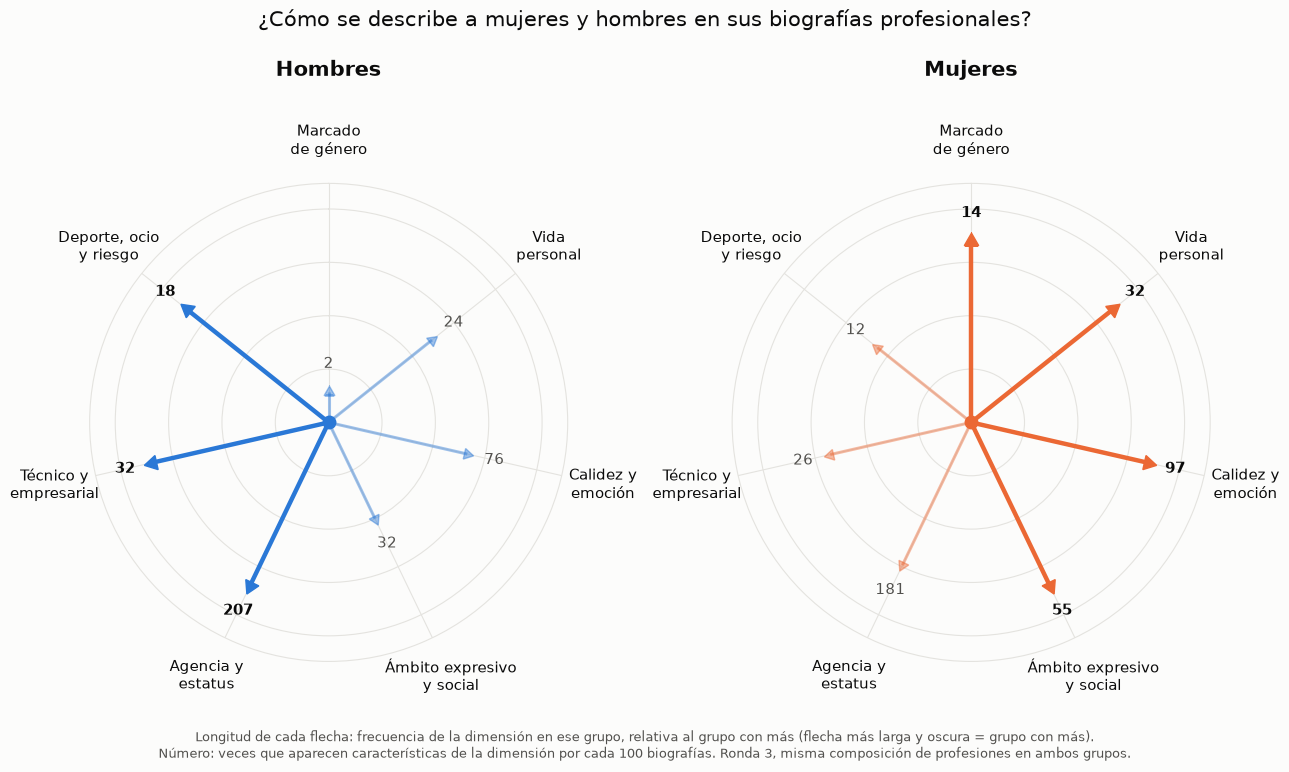

Guardado en resultados/grafico_radial_sesgo.png


In [36]:
# =====================================================================
# GRÁFICO RADIAL: hombres frente a mujeres en las 7 dimensiones
# =====================================================================
import matplotlib.pyplot as plt

ETIQUETAS = {
    "M1_marcado_genero": "Marcado\nde género", "M2_vida_personal": "Vida\npersonal",
    "M3_calidez_emocion": "Calidez y\nemoción", "M4_ambito_expresivo": "Ámbito expresivo\ny social",
    "M5_agencia_estatus": "Agencia y\nestatus", "M6_tecnico_empresarial": "Técnico y\nempresarial",
    "M7_deporte_ocio_riesgo": "Deporte, ocio\ny riesgo",
}
COLOR = {"Hombres": "#2a78d6", "Mujeres": "#eb6834"}
TINTA, TINTA_2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

def grafico_radial(met_ind, archivo=None):
    d = met_ind.copy()
    # Por cada 100 biografías: cuántas veces aparecen características de cada dimensión
    d["Hombres"] = d["media_hombres"] * 100
    d["Mujeres"] = d["media_mujeres"] * 100
    maximo = d[["Hombres", "Mujeres"]].max(axis=1)        # en cada dimensión, el grupo con más = flecha completa
    angulos = np.linspace(0, 2 * np.pi, len(d), endpoint=False)   # empieza arriba y gira en sentido horario

    fig, ejes = plt.subplots(1, 2, figsize=(13, 7.6), subplot_kw={"projection": "polar"}, facecolor=FONDO)
    for ax, grupo in zip(ejes, ["Hombres", "Mujeres"]):
        ax.set_facecolor(FONDO)
        ax.set_theta_zero_location("N")
        ax.set_theta_direction(-1)
        ax.set_thetalim(0, 2 * np.pi)
        ax.set_ylim(0, 1.12)
        ax.set_yticks([0.25, 0.5, 0.75, 1.0])
        ax.set_rlabel_position(0)
        ax.set_yticklabels([])
        ax.set_xticks(angulos)
        ax.set_xticklabels([ETIQUETAS.get(i, i) for i in d["indice"]], color=TINTA, fontsize=10.5)
        ax.tick_params(axis="x", pad=20)
        ax.grid(color=REJILLA, linewidth=0.8)
        ax.spines["polar"].set_color(REJILLA)
        otro = "Mujeres" if grupo == "Hombres" else "Hombres"
        for ang, valor, valor_otro, mx in zip(angulos, d[grupo], d[otro], maximo):
            r = valor / mx * 0.85
            gana = valor >= valor_otro
            col, lw, alfa = COLOR[grupo], (3.2 if gana else 2.2), (1 if gana else 0.45)
            ax.plot([ang, ang], [0, r], color=col, lw=lw, alpha=alfa, solid_capstyle="butt", zorder=3)
            ax.plot(ang, r, marker=(3, 0, -np.degrees(ang)), markersize=12 if gana else 9,
                    color=col, alpha=alfa, zorder=4)
            ax.text(ang, r + 0.13, f"{valor:.0f}", ha="center", va="center", zorder=5,
                    fontsize=10.5, color=TINTA if gana else TINTA_2, fontweight="bold" if gana else "normal")
        ax.plot(0, 0, "o", color=COLOR[grupo], markersize=9, zorder=5)
        ax.set_title(grupo, color=TINTA, fontsize=15, fontweight="bold", pad=34)

    fig.suptitle("¿Cómo se describe a mujeres y hombres en sus biografías profesionales?",
                 fontsize=15, color=TINTA, y=0.995)
    fig.text(0.5, 0.01,
             "Longitud de cada flecha: frecuencia de la dimensión en ese grupo, relativa al grupo con más (flecha "
             "más larga y oscura = grupo con más).\nNúmero: veces que aparecen características de la dimensión por "
             "cada 100 biografías. Ronda 3, misma composición de profesiones en ambos grupos.",
             ha="center", fontsize=9, color=TINTA_2)
    plt.tight_layout(rect=(0, 0.08, 1, 0.95))
    if archivo:
        fig.savefig(archivo, dpi=200, facecolor=FONDO, bbox_inches="tight")
    return fig

indices = pd.read_csv(RESULTADOS / "metricas_indices.csv")
grafico_radial(indices, RESULTADOS / "grafico_radial_sesgo.png")
plt.show()
print("Guardado en", RESULTADOS / "grafico_radial_sesgo.png")

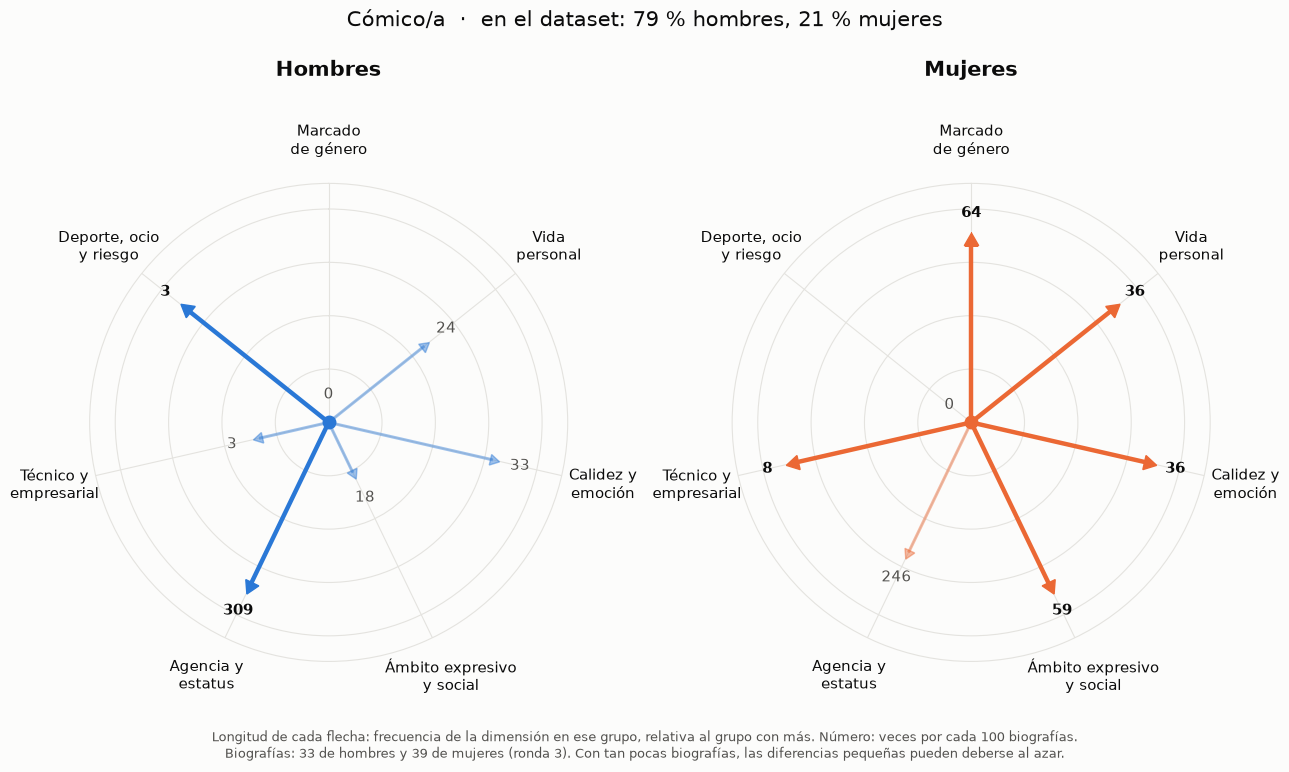

Guardados 55 gráficos en resultados/radiales_por_profesion
Nombres que puedes poner en PROFESION_A_VER: DJ, abogado/a, arquitecto/a, asistente legal, cineasta, cirujano/a, compositor/a, contable, cómico/a, dentista, dietista, docente (escuela), enfermero/a, entrenador/a personal, fotógrafo/a, ingeniero/a de software, interiorista, modelo, médico/a, pastor/a, periodista, pintor/a, poeta, profesor/a de yoga, profesor/a universitario/a, psicólogo/a, quiropráctico/a, rapero/a


In [37]:
# =====================================================================
# GRÁFICOS RADIALES POR PROFESIÓN
# =====================================================================
import matplotlib.pyplot as plt
import unicodedata

PROFESION_A_VER = "cómico/a"     # en castellano o en inglés; se muestra esta y se guardan todas

NOMBRES = {
    "accountant": "contable", "architect": "arquitecto/a", "attorney": "abogado/a",
    "chiropractor": "quiropráctico/a", "comedian": "cómico/a", "composer": "compositor/a",
    "dentist": "dentista", "dietitian": "dietista", "dj": "DJ", "filmmaker": "cineasta",
    "interior_designer": "interiorista", "journalist": "periodista", "model": "modelo",
    "nurse": "enfermero/a", "painter": "pintor/a", "paralegal": "asistente legal", "pastor": "pastor/a",
    "personal_trainer": "entrenador/a personal", "photographer": "fotógrafo/a", "physician": "médico/a",
    "poet": "poeta", "professor": "profesor/a universitario/a", "psychologist": "psicólogo/a",
    "rapper": "rapero/a", "software_engineer": "ingeniero/a de software", "surgeon": "cirujano/a",
    "teacher": "docente (escuela)", "yoga_teacher": "profesor/a de yoga",
}

ETIQUETAS = {
    "M1_marcado_genero": "Marcado\nde género", "M2_vida_personal": "Vida\npersonal",
    "M3_calidez_emocion": "Calidez y\nemoción", "M4_ambito_expresivo": "Ámbito expresivo\ny social",
    "M5_agencia_estatus": "Agencia y\nestatus", "M6_tecnico_empresarial": "Técnico y\nempresarial",
    "M7_deporte_ocio_riesgo": "Deporte, ocio\ny riesgo",
}
COLOR = {"Hombres": "#2a78d6", "Mujeres": "#eb6834"}
TINTA, TINTA_2, REJILLA, FONDO = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
DIMENSIONES = list(ETIQUETAS)

def nombre_archivo(texto):
    """'cirujano/a' -> 'cirujano-a' (sin tildes ni espacios)."""
    sin_tildes = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return re.sub(r"[^a-z0-9]+", "-", sin_tildes.lower()).strip("-")

def grafico_radial(tabla, titulo, nota, archivo=None):
    """tabla: columnas 'indice', 'media_hombres', 'media_mujeres'."""
    d = tabla.copy()
    d["Hombres"] = d["media_hombres"] * 100
    d["Mujeres"] = d["media_mujeres"] * 100
    maximo = d[["Hombres", "Mujeres"]].max(axis=1)
    angulos = np.linspace(0, 2 * np.pi, len(d), endpoint=False)

    fig, ejes = plt.subplots(1, 2, figsize=(13, 7.6), subplot_kw={"projection": "polar"}, facecolor=FONDO)
    for ax, grupo in zip(ejes, ["Hombres", "Mujeres"]):
        ax.set_facecolor(FONDO)
        ax.set_theta_zero_location("N")
        ax.set_theta_direction(-1)
        ax.set_thetalim(0, 2 * np.pi)
        ax.set_ylim(0, 1.12)
        ax.set_yticks([0.25, 0.5, 0.75, 1.0])
        ax.set_yticklabels([])
        ax.set_xticks(angulos)
        ax.set_xticklabels([ETIQUETAS.get(i, i) for i in d["indice"]], color=TINTA, fontsize=10.5)
        ax.tick_params(axis="x", pad=20)
        ax.grid(color=REJILLA, linewidth=0.8)
        ax.spines["polar"].set_color(REJILLA)
        otro = "Mujeres" if grupo == "Hombres" else "Hombres"
        for ang, valor, valor_otro, mx in zip(angulos, d[grupo], d[otro], maximo):
            if not mx > 0:                      # nadie tiene esa dimensión: sin flecha
                ax.text(ang, 0.13, "0", ha="center", va="center", fontsize=10.5, color=TINTA_2)
                continue
            r = valor / mx * 0.85
            gana = valor >= valor_otro
            col, lw, alfa = COLOR[grupo], (3.2 if gana else 2.2), (1 if gana else 0.45)
            if r > 0:
                ax.plot([ang, ang], [0, r], color=col, lw=lw, alpha=alfa, solid_capstyle="butt", zorder=3)
                ax.plot(ang, r, marker=(3, 0, -np.degrees(ang)), markersize=12 if gana else 9,
                        color=col, alpha=alfa, zorder=4)
            ax.text(ang, r + 0.13, f"{valor:.0f}", ha="center", va="center", zorder=5,
                    fontsize=10.5, color=TINTA if gana else TINTA_2, fontweight="bold" if gana else "normal")
        ax.plot(0, 0, "o", color=COLOR[grupo], markersize=9, zorder=5)
        ax.set_title(grupo, color=TINTA, fontsize=15, fontweight="bold", pad=34)

    fig.suptitle(titulo, fontsize=15, color=TINTA, y=0.995)
    fig.text(0.5, 0.01, nota, ha="center", fontsize=9, color=TINTA_2)
    plt.tight_layout(rect=(0, 0.08, 1, 0.95))
    if archivo:
        fig.savefig(archivo, dpi=200, facecolor=FONDO, bbox_inches="tight")
    return fig

# --- Un gráfico por profesión ---
carpeta = RESULTADOS / "radiales_por_profesion"
carpeta.mkdir(exist_ok=True)

for prof, g in v3.groupby("profesion"):
    medias = g.groupby("mujer")[DIMENSIONES].mean()
    if 0 not in medias.index or 1 not in medias.index:
        continue
    tabla = pd.DataFrame({"indice": DIMENSIONES,
                          "media_hombres": medias.loc[0].values,
                          "media_mujeres": medias.loc[1].values})
    n_h, n_m = (g["mujer"] == 0).sum(), (g["mujer"] == 1).sum()
    nombre = NOMBRES.get(prof, prof)
    titulo = (f"{nombre[0].upper() + nombre[1:]}  ·  en el dataset: "
              f"{100 - comp[prof]:.0f} % hombres, {comp[prof]:.0f} % mujeres")
    nota = (f"Longitud de cada flecha: frecuencia de la dimensión en ese grupo, relativa al grupo con más. "
            f"Número: veces por cada 100 biografías.\nBiografías: {n_h} de hombres y {n_m} de mujeres "
            f"(ronda 3). Con tan pocas biografías, las diferencias pequeñas pueden deberse al azar.")
    fig = grafico_radial(tabla, titulo, nota, carpeta / f"radial_{nombre_archivo(nombre)}.png")
    if PROFESION_A_VER in (prof, nombre):
        plt.show()
    else:
        plt.close(fig)

print(f"Guardados {len(list(carpeta.glob('radial_*.png')))} gráficos en {carpeta}")
print("Nombres que puedes poner en PROFESION_A_VER:", ", ".join(sorted(NOMBRES.values())))

Guardamos resultados:

In [40]:
import shutil
shutil.make_archive("salidas_parte_1", "zip", "resultados")
print("Creado: salidas_parte_1.zip")

Creado: salidas_parte_1.zip
